In [5]:
# Imports
import os, cv2, numpy as np, pandas as pd
from pathlib import Path
from collections import defaultdict
import random
from scipy import ndimage  # Per distance transform (Boundary Loss)

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader

from sklearn.model_selection import train_test_split
from sklearn.metrics import jaccard_score, f1_score, precision_score, recall_score, accuracy_score

from tqdm.auto import tqdm  # tqdm.auto per migliore compatibilità notebook
import matplotlib.pyplot as plt
import seaborn as sns

def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

set_seed(42)

In [6]:
!pip install transformers segmentation-models-pytorch ranger21 -q
from transformers import SegformerForSemanticSegmentation
from ranger21 import Ranger21

In [7]:
class Config:
    NUM_EPOCHS = 60
    BATCH_SIZE = 3
    LEARNING_RATE = 4e-5
    WEIGHT_DECAY = 5e-5
    TARGET_SIZE = 512
    NUM_CLASSES = 2
    

    DETECTION_WEIGHT = 2.0
    DICE_WEIGHT = 1.5
    LOVASZ_WEIGHT = 2.0
    TVERSKY_WEIGHT = 2.0
    EDGE_FOCAL_WEIGHT = 1.5
    BOUNDARY_WEIGHT = 2.5
    CONTOUR_WEIGHT = 1.5
    EMPTY_WEIGHT = 5.0
    AUX_WEIGHT = 0.3
    

    TVERSKY_ALPHA = 0.5
    TVERSKY_BETA = 0.5
    

    DETECTION_THRESHOLD = 0.6
    GATING_WARMUP_EPOCHS = 10
    

    PATIENCE = 10
    

    CLASS_WEIGHTS = [0.3, 1.0]
    
    SEGFORMER_MODEL = "nvidia/segformer-b2-finetuned-ade-512-512"
    DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

print(f"Device: {Config.DEVICE}")
print(f"Mode: BINARY SEGMENTATION (2 classes)")
print(f"✅ V2: Lovász Loss + Cosine Annealing + Augmentation Avanzata")
print(f"✅ DETECTION_THRESHOLD={Config.DETECTION_THRESHOLD}, PATIENCE={Config.PATIENCE}")
print(f"✅ Lovász Weight={Config.LOVASZ_WEIGHT}, Dice Weight={Config.DICE_WEIGHT}")

Device: cuda
Mode: BINARY SEGMENTATION (2 classes)
✅ V2: Lovász Loss + Cosine Annealing + Augmentation Avanzata
✅ DETECTION_THRESHOLD=0.6, PATIENCE=10
✅ Lovász Weight=2.0, Dice Weight=1.5


## Data Loading

In [ ]:
def load_patient_data(csv_path, images_dir):
    df = pd.read_excel(csv_path)
    patients_dict = defaultdict(list)
    
    for _, row in tqdm(df.iterrows(), total=len(df), desc="Loading data"):
        img_name, mask_name, label = row['US'], row['MASK'], row['LABEL']
        patient_id = Path(img_name).stem.split('_')[0]
        
        patients_dict[patient_id].append({
            'img_path': str(Path(images_dir) / img_name),
            'mask_path': str(Path(images_dir) / mask_name),
            'img_name': img_name,
            'label': label
        })
    
    patients = []
    for pid, samples in sorted(patients_dict.items(), key=lambda x: int(x[0])):
        labels = [s['label'] for s in samples]
        major_label = int(np.argmax(np.bincount(labels)))
        patients.append({'patient_id': pid, 'samples': samples, 'major_label': major_label})
    
    return patients

INPUT_DIRECTORY = '/kaggle/input/breast-lesions/'
IMG_DIRECTORY = INPUT_DIRECTORY + 'train/images'
LABELS_PATH = INPUT_DIRECTORY + 'train/train_metadata.xlsx'

train_data = load_patient_data(LABELS_PATH, IMG_DIRECTORY)
print(f"✅ Loaded {len(train_data)} patients")

## Preprocessing

In [9]:
def resize_with_padding(img, mask=None, target_size=512):
    h, w = img.shape[:2]
    scale = target_size / max(h, w)
    new_h, new_w = int(h * scale), int(w * scale)
    
    img_resized = cv2.resize(img, (new_w, new_h), interpolation=cv2.INTER_CUBIC)
    if mask is not None:
        mask_resized = cv2.resize(mask, (new_w, new_h), interpolation=cv2.INTER_NEAREST)
    
    pad_h, pad_w = target_size - new_h, target_size - new_w
    pad_top, pad_left = pad_h // 2, pad_w // 2
    pad_bottom, pad_right = pad_h - pad_top, pad_w - pad_left
    
    img_padded = cv2.copyMakeBorder(img_resized, pad_top, pad_bottom, pad_left, pad_right, cv2.BORDER_CONSTANT, value=0)
    
    if mask is not None:
        mask_padded = cv2.copyMakeBorder(mask_resized, pad_top, pad_bottom, pad_left, pad_right, cv2.BORDER_CONSTANT, value=0)
        return img_padded, mask_padded
    return img_padded

def has_colors(img, sat_thresh=40, delta_thresh=20, white_brightness_thresh=200, white_sat_thresh=30, red_sat_thresh=50, blue_sat_thresh=50):
    hsv = cv2.cvtColor(img, cv2.COLOR_BGR2HSV)
    h, s, v = cv2.split(hsv)
    b, g, r = cv2.split(img)
    r, g, b = r.astype(np.int16), g.astype(np.int16), b.astype(np.int16)
    
    delta = np.maximum.reduce([np.abs(r - g), np.abs(r - b), np.abs(g - b)])
    mask = np.logical_or.reduce([
        np.logical_and(delta > delta_thresh, s > sat_thresh),
        (s < white_sat_thresh) & (v > white_brightness_thresh),
        ((h < 15) | (h > 165)) & (s > red_sat_thresh),
        ((h >= 100) & (h <= 130)) & (s > blue_sat_thresh)
    ]).astype(np.uint8) * 255
    
    return np.sum(mask) > 0, mask

def inpaint(img):
    detected, mask = has_colors(img)
    return cv2.inpaint(img, mask, 3, cv2.INPAINT_TELEA) if detected else img

def apply_median_filter(image, kernel_size=5):
    return cv2.medianBlur(image.astype(np.uint8), kernel_size)

def apply_clahe(image, clip_limit=2.0, tile_grid_size=(8, 8)):
    clahe = cv2.createCLAHE(clipLimit=clip_limit, tileGridSize=tile_grid_size)
    return clahe.apply(image)

def apply_zscore_normalization(image):
    image = image.astype(np.float32)
    mean, std = np.mean(image), np.std(image)
    return (image - mean) / std if std > 0 else image - mean

## Augmentation

In [10]:
class AdvancedAugmentation:

    def __init__(self, epoch=0):
        self.epoch = epoch
        np.random.seed(42 + epoch)
        
    def elastic_transform(self, image, mask, alpha=30, sigma=4):

        random_state = np.random.RandomState(None)
        shape = image.shape
        
        dx = cv2.GaussianBlur((random_state.rand(*shape) * 2 - 1).astype(np.float32), (0, 0), sigma) * alpha
        dy = cv2.GaussianBlur((random_state.rand(*shape) * 2 - 1).astype(np.float32), (0, 0), sigma) * alpha
        
        x, y = np.meshgrid(np.arange(shape[1]), np.arange(shape[0]))
        map_x = (x + dx).astype(np.float32)
        map_y = (y + dy).astype(np.float32)
        
        image_out = cv2.remap(image.astype(np.float32), map_x, map_y, cv2.INTER_LINEAR, borderValue=0)
        mask_out = cv2.remap(mask.astype(np.float32), map_x, map_y, cv2.INTER_NEAREST, borderValue=0)
        
        return image_out, mask_out.astype(np.uint8)
    
    def grid_distortion(self, image, mask, num_steps=5, distort_limit=0.2):

        h, w = image.shape
        

        x_steps = np.linspace(0, w, num_steps)
        y_steps = np.linspace(0, h, num_steps)
        

        x_offsets = np.zeros(num_steps)
        y_offsets = np.zeros(num_steps)
        x_offsets[1:-1] = np.random.uniform(-distort_limit * w / num_steps, 
                                              distort_limit * w / num_steps, num_steps - 2)
        y_offsets[1:-1] = np.random.uniform(-distort_limit * h / num_steps, 
                                              distort_limit * h / num_steps, num_steps - 2)
        

        map_x = np.zeros((h, w), dtype=np.float32)
        map_y = np.zeros((h, w), dtype=np.float32)
        
        for i in range(h):
            for j in range(w):
                map_x[i, j] = j + np.interp(j, x_steps, x_offsets)
                map_y[i, j] = i + np.interp(i, y_steps, y_offsets)
        
        map_x = np.clip(map_x, 0, w - 1)
        map_y = np.clip(map_y, 0, h - 1)
        
        image_out = cv2.remap(image.astype(np.float32), map_x, map_y, cv2.INTER_LINEAR, borderValue=0)
        mask_out = cv2.remap(mask.astype(np.float32), map_x, map_y, cv2.INTER_NEAREST, borderValue=0)
        
        return image_out, mask_out.astype(np.uint8)
        
    def __call__(self, image, mask):
        h, w = image.shape
        

        if np.random.rand() > 0.5:
            image, mask = np.fliplr(image).copy(), np.fliplr(mask).copy()
        

        if np.random.rand() > 0.5:
            image, mask = np.flipud(image).copy(), np.flipud(mask).copy()
        

        if np.random.rand() > 0.5:
            angle = np.random.uniform(-15, 15)  # ↑ Range aumentato
            M = cv2.getRotationMatrix2D((w // 2, h // 2), angle, 1.0)
            image = cv2.warpAffine(image, M, (w, h), flags=cv2.INTER_LINEAR, borderValue=0)
            mask = cv2.warpAffine(mask, M, (w, h), flags=cv2.INTER_NEAREST, borderValue=0)
        

        if np.random.rand() > 0.7:
            image, mask = self.elastic_transform(image, mask, alpha=25, sigma=4)
        

        if np.random.rand() > 0.75:
            image, mask = self.grid_distortion(image, mask, num_steps=4, distort_limit=0.15)
        

        if np.random.rand() > 0.5:
            image = np.clip(image * np.random.uniform(0.85, 1.15), image.min(), image.max())
        

        if np.random.rand() > 0.5:
            mean = image.mean()
            image = np.clip((image - mean) * np.random.uniform(0.85, 1.15) + mean, image.min(), image.max())
        

        if np.random.rand() > 0.8:
            noise = np.random.normal(0, 0.02 * (image.max() - image.min()), image.shape)
            image = np.clip(image + noise, image.min(), image.max())
        
        return image.astype(np.float32), mask

## Dataset

In [11]:
class SegmentationDataset(Dataset):
    def __init__(self, patients, augment=False, epoch=0):
        self.samples = []
        for patient in patients:
            self.samples.extend(patient['samples'])
        self.augment = augment
        self.epoch = epoch
        self.augmentation = AdvancedAugmentation(epoch) if augment else None
    
    def set_epoch(self, epoch):
        self.epoch = epoch
        if self.augment:
            self.augmentation = AdvancedAugmentation(epoch)
    
    def __len__(self):
        return len(self.samples)
    
    def __getitem__(self, idx):
        sample = self.samples[idx]
        
        img_bgr = cv2.imread(sample['img_path'])
        mask_bgr = cv2.imread(sample['mask_path'])
        mask_gray = cv2.cvtColor(mask_bgr, cv2.COLOR_BGR2GRAY)
        
        img_inpainted = inpaint(img_bgr)
        img_gray = cv2.cvtColor(img_inpainted, cv2.COLOR_BGR2GRAY)
        img_denoised = apply_median_filter(img_gray)
        img_resized, mask_resized = resize_with_padding(img_denoised, mask_gray, Config.TARGET_SIZE)
        img_clahe = apply_clahe(img_resized)
        img_normalized = apply_zscore_normalization(img_clahe)
        
        label = sample['label']
        binary_mask = (mask_resized > 127).astype(np.uint8)
        

        if label == 2:  # No lesion
            seg_mask = np.zeros_like(binary_mask, dtype=np.uint8)
            has_lesion = 0
        else:
            seg_mask = binary_mask.copy()  # Già 0/1
            has_lesion = 1
        
        if self.augment and self.augmentation is not None:
            img_normalized, seg_mask = self.augmentation(img_normalized, seg_mask)
        
        img_normalized = np.ascontiguousarray(img_normalized)
        seg_mask = np.ascontiguousarray(seg_mask)
        
        return {
            'image': torch.from_numpy(img_normalized).unsqueeze(0).float(),
            'mask': torch.from_numpy(seg_mask).long(),
            'has_lesion': torch.tensor(has_lesion, dtype=torch.long),
            'label': torch.tensor(label, dtype=torch.long)
        }

## Model

In [12]:
class ContourAwareDecoder(nn.Module):
    def __init__(self, in_channels_list=[64, 128, 320, 512]):
        super().__init__()

        self.projections = nn.ModuleList([
            nn.Sequential(
                nn.Conv2d(c, 64, 1),
                nn.BatchNorm2d(64),
                nn.ReLU(inplace=True)
            ) for c in in_channels_list
        ])
        
        self.fusion = nn.Sequential(
            nn.Conv2d(64 * 4, 128, 3, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(inplace=True),
            nn.Conv2d(128, 64, 3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(inplace=True),
        )
        
        self.contour_head = nn.Conv2d(64, 1, 1)
    
    def forward(self, hidden_states, target_size):
        projected = []
        for i, (proj, h) in enumerate(zip(self.projections, hidden_states)):
            p = proj(h)
            p = F.interpolate(p, size=target_size, mode='bilinear', align_corners=False)
            projected.append(p)
        
        fused = torch.cat(projected, dim=1)
        fused = self.fusion(fused)
        
        contour_logits = self.contour_head(fused)
        return contour_logits


class DualHeadSegFormerDeepSup(nn.Module):
    def __init__(self, num_classes=2):
        super().__init__()
        
        self.segformer = SegformerForSemanticSegmentation.from_pretrained(
            Config.SEGFORMER_MODEL, num_labels=num_classes, ignore_mismatched_sizes=True
        )

        original_conv = self.segformer.segformer.encoder.patch_embeddings[0].proj
        self.segformer.segformer.encoder.patch_embeddings[0].proj = nn.Conv2d(
            1, original_conv.out_channels, kernel_size=original_conv.kernel_size,
            stride=original_conv.stride, padding=original_conv.padding
        )
        self.segformer.segformer.encoder.patch_embeddings[0].proj.weight.data = \
            original_conv.weight.data.mean(dim=1, keepdim=True)
        
        self.aux_heads = nn.ModuleList([
            nn.Conv2d(64, num_classes, 1),
            nn.Conv2d(128, num_classes, 1),
            nn.Conv2d(320, num_classes, 1),
        ])
        
        self.contour_decoder = ContourAwareDecoder(in_channels_list=[64, 128, 320, 512])
        
        self.detection_head = nn.Sequential(
            nn.Linear(num_classes, 128), nn.ReLU(inplace=True),
            nn.Dropout(0.3), 
            nn.Linear(128, 64), nn.ReLU(inplace=True),
            nn.Linear(64, 2)
        )
    
    def forward(self, x, return_aux=False):
        encoder_outputs = self.segformer.segformer.encoder(
            x, output_hidden_states=True, return_dict=True
        )
        hidden_states = encoder_outputs.hidden_states
        
        main_logits = self.segformer.decode_head(hidden_states)
        main_logits = F.interpolate(
            main_logits, size=x.shape[2:], mode='bilinear', align_corners=False
        )
        
        global_features = F.adaptive_avg_pool2d(main_logits, (1, 1)).squeeze(-1).squeeze(-1)
        detection_logits = self.detection_head(global_features)
        
        if return_aux and self.training:
            aux_outputs = []
            for i, aux_head in enumerate(self.aux_heads):
                aux = aux_head(hidden_states[i])
                aux = F.interpolate(aux, size=x.shape[2:], mode='bilinear', align_corners=False)
                aux_outputs.append(aux)
            
            contour_logits = self.contour_decoder(hidden_states, x.shape[2:])
            
            return detection_logits, main_logits, aux_outputs, contour_logits
        
        return detection_logits, main_logits

## Loss Functions

In [13]:
class DiceLoss(nn.Module):
    def __init__(self, smooth=1.0):
        super().__init__()
        self.smooth = smooth
    
    def forward(self, pred, target):
        pred_probs = F.softmax(pred, dim=1)
        num_classes = pred.shape[1]
        target_one_hot = F.one_hot(target, num_classes).permute(0, 3, 1, 2).float()
        
        dice_scores = []
        for c in range(num_classes):
            pred_c = pred_probs[:, c, :, :].contiguous().view(-1)
            target_c = target_one_hot[:, c, :, :].contiguous().view(-1)
            intersection = (pred_c * target_c).sum()
            union = pred_c.sum() + target_c.sum()
            dice = (2. * intersection + self.smooth) / (union + self.smooth)
            dice_scores.append(dice)
        
        return 1 - torch.stack(dice_scores).mean()


class LovaszSoftmaxLoss(nn.Module):
    def __init__(self):
        super().__init__()
    
    def lovasz_grad(self, gt_sorted):
        gts = gt_sorted.sum()
        intersection = gts - gt_sorted.float().cumsum(0)
        union = gts + (1 - gt_sorted).float().cumsum(0)
        jaccard = 1.0 - intersection / union
        if len(gt_sorted) > 1:
            jaccard[1:] = jaccard[1:] - jaccard[:-1]
        return jaccard
    
    def lovasz_softmax_flat(self, probas, labels):
        if probas.numel() == 0:
            return probas * 0.
        
        C = probas.shape[0]
        losses = []
        
        for c in range(C):
            fg = (labels == c).float()
            if fg.sum() == 0:
                continue
            errors = (fg - probas[c]).abs()
            errors_sorted, perm = torch.sort(errors, descending=True)
            fg_sorted = fg[perm]
            
            gts = fg_sorted.sum()
            intersection = gts - fg_sorted.cumsum(0)
            union = gts + (1 - fg_sorted).cumsum(0)
            jaccard = 1.0 - intersection / (union + 1e-8)
            jaccard = torch.cat([jaccard[:1], jaccard[1:] - jaccard[:-1]], dim=0)
            
            loss = (errors_sorted * jaccard).sum()
            losses.append(loss)
        
        return sum(losses) / max(len(losses), 1)
    
    def forward(self, pred, target):
        probas = F.softmax(pred, dim=1)
        B, C, H, W = probas.shape
        
        probas = probas.permute(0, 2, 3, 1).reshape(-1, C).T  # (C, B*H*W)
        target = target.view(-1)  # (B*H*W,)
        
        return self.lovasz_softmax_flat(probas, target)


class TverskyLoss(nn.Module):
    def __init__(self, alpha=0.3, beta=0.7, smooth=1.0):
        super().__init__()
        self.alpha = alpha
        self.beta = beta
        self.smooth = smooth
    
    def forward(self, pred, target, num_classes=2):
        pred_probs = F.softmax(pred, dim=1)
        target_oh = F.one_hot(target, num_classes).permute(0, 3, 1, 2).float()
        
        pred_c = pred_probs[:, 1].contiguous().view(-1)
        target_c = target_oh[:, 1].contiguous().view(-1)
        
        TP = (pred_c * target_c).sum()
        FP = (pred_c * (1 - target_c)).sum()
        FN = ((1 - pred_c) * target_c).sum()
        
        tversky = (TP + self.smooth) / (TP + self.alpha * FP + self.beta * FN + self.smooth)
        return 1 - tversky


class BoundaryLoss(nn.Module):
    def __init__(self):
        super().__init__()
    
    def compute_distance_map(self, mask):
        batch_size = mask.shape[0]
        dist_maps = []
        
        for b in range(batch_size):
            m = mask[b].cpu().numpy().astype(np.uint8)
            if m.sum() == 0:
                dist_maps.append(np.zeros_like(m, dtype=np.float32))
            else:
                dist_inside = ndimage.distance_transform_edt(m)
                dist_outside = ndimage.distance_transform_edt(1 - m)
                signed_dist = dist_outside - dist_inside
                max_val = max(abs(signed_dist.min()), abs(signed_dist.max()), 1)
                signed_dist = signed_dist / max_val
                dist_maps.append(signed_dist.astype(np.float32))
        
        return torch.from_numpy(np.stack(dist_maps)).float()
    
    def forward(self, pred, target):
        pred_probs = F.softmax(pred, dim=1)[:, 1]  # Probabilità lesione
        dist_map = self.compute_distance_map(target).to(pred.device)
        boundary_loss = (pred_probs * dist_map).mean()
        return boundary_loss


class ContourLoss(nn.Module):
    def __init__(self):
        super().__init__()
    
    def extract_contours(self, mask):
        batch_size = mask.shape[0]
        contours = []
        
        for b in range(batch_size):
            m = mask[b].cpu().numpy().astype(np.uint8)
            if m.sum() == 0:
                contours.append(np.zeros_like(m, dtype=np.float32))
            else:
                kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (3, 3))
                eroded = cv2.erode(m, kernel, iterations=1)
                contour = (m - eroded).astype(np.float32)
                contours.append(contour)
        
        return torch.from_numpy(np.stack(contours)).float()
    
    def forward(self, contour_logits, target):
        gt_contours = self.extract_contours(target).to(contour_logits.device)
        pred_probs = torch.sigmoid(contour_logits.squeeze(1))
        
        pos_weight = (gt_contours.numel() - gt_contours.sum()) / (gt_contours.sum() + 1)
        pos_weight = min(pos_weight, 20.0)
        
        bce = F.binary_cross_entropy(pred_probs, gt_contours, reduction='none')
        weighted_bce = bce * (1 + pos_weight * gt_contours)
        return weighted_bce.mean()


class EdgeAwareFocalLoss(nn.Module):
    def __init__(self, alpha=[0.3, 1.0], gamma=2.5, edge_weight=3.0):
        super().__init__()
        self.alpha = alpha
        self.gamma = gamma
        self.edge_weight = edge_weight
    
    def forward(self, pred, target):
        target_np = target.cpu().numpy().astype(np.uint8)
        edges = np.zeros_like(target_np, dtype=np.float32)
        
        for b in range(target_np.shape[0]):
            mask_c = (target_np[b] == 1).astype(np.uint8)
            if mask_c.sum() > 0:
                kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (5, 5))
                eroded = cv2.erode(mask_c, kernel, iterations=1)
                dilated = cv2.dilate(mask_c, kernel, iterations=1)
                edges[b] = (dilated - eroded).astype(np.float32)
        
        edges = torch.from_numpy(np.clip(edges, 0, 1)).to(pred.device).float()
        
        pred_flat = pred.permute(0, 2, 3, 1).reshape(-1, pred.shape[1])
        target_flat = target.reshape(-1)
        edges_flat = edges.reshape(-1)
        
        class_weights = torch.tensor(self.alpha, device=pred.device, dtype=torch.float32)
        ce_loss = F.cross_entropy(pred_flat, target_flat, weight=class_weights, reduction='none')
        
        p_t = torch.exp(-ce_loss)
        focal = (1 - p_t) ** self.gamma * ce_loss
        
        edge_weights = 1.0 + self.edge_weight * edges_flat
        return (focal * edge_weights).mean()


class CombinedSegmentationLoss(nn.Module):
    def __init__(self, config):
        super().__init__()
        self.config = config
        self.detection_bce = nn.CrossEntropyLoss()
        self.dice_loss = DiceLoss()
        self.lovasz_loss = LovaszSoftmaxLoss()  # ✅ NEW
        self.tversky_loss = TverskyLoss(alpha=config.TVERSKY_ALPHA, beta=config.TVERSKY_BETA)
        self.edge_focal = EdgeAwareFocalLoss(alpha=config.CLASS_WEIGHTS, gamma=2.5, edge_weight=3.0)
        self.boundary_loss = BoundaryLoss()
        self.contour_loss = ContourLoss()
    
    def forward(self, detection_logits, segmentation_logits, has_lesion, mask, 
                aux_outputs=None, contour_logits=None):
        device = detection_logits.device
        
        detection_loss = self.detection_bce(detection_logits, has_lesion)
        
        lesion_mask = has_lesion == 1
        if lesion_mask.sum() > 0:
            seg_logits = segmentation_logits[lesion_mask]
            mask_les = mask[lesion_mask]
            
            dice_loss = self.dice_loss(seg_logits, mask_les)
            lovasz_loss = self.lovasz_loss(seg_logits, mask_les)  # ✅ NEW
            tversky_loss = self.tversky_loss(seg_logits, mask_les)
            edge_focal_loss = self.edge_focal(seg_logits, mask_les)
            boundary_loss = self.boundary_loss(seg_logits, mask_les)
        else:
            dice_loss = lovasz_loss = tversky_loss = edge_focal_loss = boundary_loss = torch.tensor(0.0, device=device)
        
        empty_mask = has_lesion == 0
        empty_penalty = torch.tensor(0.0, device=device)
        if empty_mask.sum() > 0:
            seg_empty = segmentation_logits[empty_mask]
            probs = F.softmax(seg_empty, dim=1)
            lesion_probs = probs[:, 1:].sum(dim=1)
            empty_penalty = (lesion_probs ** 2).mean()
        
        aux_loss = torch.tensor(0.0, device=device)
        if aux_outputs is not None and lesion_mask.sum() > 0:
            for aux_logits in aux_outputs:
                aux_les = aux_logits[lesion_mask]
                aux_loss += self.dice_loss(aux_les, mask_les)
            aux_loss /= len(aux_outputs)
        
        contour_loss = torch.tensor(0.0, device=device)
        if contour_logits is not None and lesion_mask.sum() > 0:
            contour_logits_les = contour_logits[lesion_mask]
            contour_loss = self.contour_loss(contour_logits_les, mask_les)
        
        total_loss = (
            self.config.DETECTION_WEIGHT * detection_loss +
            self.config.DICE_WEIGHT * dice_loss +
            self.config.LOVASZ_WEIGHT * lovasz_loss +  # ✅ NEW
            self.config.TVERSKY_WEIGHT * tversky_loss +
            self.config.EDGE_FOCAL_WEIGHT * edge_focal_loss +
            self.config.BOUNDARY_WEIGHT * boundary_loss +
            self.config.CONTOUR_WEIGHT * contour_loss +
            self.config.EMPTY_WEIGHT * empty_penalty +
            self.config.AUX_WEIGHT * aux_loss
        )
        
        return {
            'total': total_loss,
            'detection': detection_loss,
            'dice': dice_loss,
            'lovasz': lovasz_loss,  # ✅ NEW
            'tversky': tversky_loss,
            'edge_focal': edge_focal_loss,
            'boundary': boundary_loss,
            'contour': contour_loss,
            'empty_penalty': empty_penalty,
            'aux': aux_loss
        }

## Training Functions

In [14]:
def compute_segmentation_metrics(pred_masks, gt_masks, num_classes=2):
    pred_binary = (pred_masks > 0).astype(int).flatten()
    gt_binary = (gt_masks > 0).astype(int).flatten()
    
    metrics = {
        'lesion_dice': f1_score(gt_binary, pred_binary, zero_division=0),
        'lesion_precision': precision_score(gt_binary, pred_binary, zero_division=0),
        'lesion_recall': recall_score(gt_binary, pred_binary, zero_division=0),
    }
    
    metrics['mean_lesion_dice'] = metrics['lesion_dice']
    metrics['mean_lesion_recall'] = metrics['lesion_recall']
    metrics['mean_lesion_precision'] = metrics['lesion_precision']
    
    return metrics


def train_one_epoch(model, dataloader, optimizer, criterion, device, epoch, dataset):
    model.train()
    total_losses = {
        'total': 0, 'detection': 0, 'dice': 0, 'tversky': 0, 
        'edge_focal': 0, 'boundary': 0, 'contour': 0, 'empty_penalty': 0, 'aux': 0
    }
    detection_correct = total = 0
    
    dataset.set_epoch(epoch)
    
    pbar = tqdm(dataloader, desc=f"Train {epoch+1}", leave=False)
    
    for batch in pbar:
        images = batch['image'].to(device)
        masks = batch['mask'].to(device)
        has_lesion = batch['has_lesion'].to(device)
        
        optimizer.zero_grad()
        
        outputs = model(images, return_aux=True)
        if len(outputs) == 4:
            detection_logits, segmentation_logits, aux_outputs, contour_logits = outputs
        elif len(outputs) == 3:
            detection_logits, segmentation_logits, aux_outputs = outputs
            contour_logits = None
        else:
            detection_logits, segmentation_logits = outputs
            aux_outputs = contour_logits = None
        
        losses = criterion(detection_logits, segmentation_logits, has_lesion, masks, 
                          aux_outputs, contour_logits)
        
        losses['total'].backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
        optimizer.step()
        
        for key in total_losses:
            if key in losses:
                total_losses[key] += losses[key].item()
        
        _, det_pred = torch.max(detection_logits, 1)
        detection_correct += (det_pred == has_lesion).sum().item()
        total += has_lesion.size(0)
        
        pbar.set_postfix({
            'loss': f"{losses['total'].item():.3f}", 
            'dice': f"{losses['dice'].item():.3f}",
            'bnd': f"{losses['boundary'].item():.3f}"
        })
    
    n_batches = len(dataloader)
    avg_losses = {k: v / n_batches for k, v in total_losses.items()}
    
    return avg_losses, detection_correct / total


def validate(model, dataloader, criterion, device, epoch=0):
    model.eval()
    total_losses = {
        'total': 0, 'detection': 0, 'dice': 0, 'tversky': 0, 
        'edge_focal': 0, 'boundary': 0, 'contour': 0, 'empty_penalty': 0, 'aux': 0
    }
    
    all_pred_masks = []
    all_gt_masks = []
    all_detection_preds = []
    all_detection_labels = []
    
    apply_gating = epoch >= Config.GATING_WARMUP_EPOCHS
    
    with torch.no_grad():
        for batch in tqdm(dataloader, desc="Val", leave=False):
            images = batch['image'].to(device)
            masks = batch['mask'].to(device)
            has_lesion = batch['has_lesion'].to(device)
            
            detection_logits, segmentation_logits = model(images, return_aux=False)
            losses = criterion(detection_logits, segmentation_logits, has_lesion, masks, None, None)
            
            for key in total_losses:
                if key in losses:
                    total_losses[key] += losses[key].item()
            
            det_probs = F.softmax(detection_logits, dim=1)
            det_confidence = det_probs[:, 1]  # Probabilità classe "lesion"
            det_pred = torch.argmax(det_probs, dim=1)
            
            seg_pred = torch.argmax(segmentation_logits, dim=1)
            
            if apply_gating:
                for b in range(seg_pred.shape[0]):
                    if det_confidence[b] < Config.DETECTION_THRESHOLD:
                        seg_pred[b] = 0
            
            all_pred_masks.append(seg_pred.cpu().numpy())
            all_gt_masks.append(masks.cpu().numpy())
            all_detection_preds.extend(det_pred.cpu().numpy())
            all_detection_labels.extend(has_lesion.cpu().numpy())
    
    n_batches = len(dataloader)
    avg_losses = {k: v / n_batches for k, v in total_losses.items()}
    
    all_pred_masks = np.concatenate(all_pred_masks, axis=0)
    all_gt_masks = np.concatenate(all_gt_masks, axis=0)
    
    detection_acc = accuracy_score(all_detection_labels, all_detection_preds)
    seg_metrics = compute_segmentation_metrics(all_pred_masks, all_gt_masks)
    
    metrics = {'detection_acc': detection_acc, **seg_metrics}
    
    return avg_losses, metrics, all_pred_masks, all_gt_masks


## Visualization

In [15]:
def postprocess_mask(mask, min_area=80):
    mask_refined = mask.copy().astype(np.uint8)
    
    lesion_mask = (mask_refined > 0).astype(np.uint8)
    if lesion_mask.sum() == 0:
        return mask_refined
    
    kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (5, 5))
    closed = cv2.morphologyEx(lesion_mask, cv2.MORPH_CLOSE, kernel)
    opened = cv2.morphologyEx(closed, cv2.MORPH_OPEN, kernel)
    
    num_labels, labels, stats, _ = cv2.connectedComponentsWithStats(opened, connectivity=8)
    
    refined_mask = np.zeros_like(opened)
    for i in range(1, num_labels):
        if stats[i, cv2.CC_STAT_AREA] >= min_area:
            refined_mask[labels == i] = 1
    
    return refined_mask

def visualize_segmentation_results(images, gt_masks, pred_masks, n_samples=6, return_fig=False):
    n_samples = min(n_samples, len(images))
    
    fig, axes = plt.subplots(n_samples, 4, figsize=(16, 4*n_samples))
    if n_samples == 1:
        axes = axes.reshape(1, -1)
    
    for i in range(n_samples):
        img = images[i, 0] if len(images.shape) == 4 else images[i]
        gt = (gt_masks[i] > 0).astype(np.uint8)  # Binarizza GT
        pred = (pred_masks[i] > 0).astype(np.uint8)  # Binarizza pred
        
        img_display = ((img - img.min()) / (img.max() - img.min() + 1e-8) * 255).astype(np.uint8)
        img_rgb = cv2.cvtColor(img_display, cv2.COLOR_GRAY2RGB)
        
        gt_overlay = img_rgb.copy()
        gt_overlay[gt == 1] = [0, 255, 0]
        gt_overlay = cv2.addWeighted(img_rgb, 0.6, gt_overlay, 0.4, 0)
        
        pred_overlay = img_rgb.copy()
        pred_overlay[pred == 1] = [0, 255, 0]
        pred_overlay = cv2.addWeighted(img_rgb, 0.6, pred_overlay, 0.4, 0)
        
        diff_rgb = img_rgb.copy()
        fp = (pred == 1) & (gt == 0)  # False Positive
        fn = (pred == 0) & (gt == 1)  # False Negative
        diff_rgb[fp] = [255, 0, 0]  # Rosso = FP
        diff_rgb[fn] = [0, 0, 255]  # Blu = FN
        
        axes[i, 0].imshow(img_display, cmap='gray')
        axes[i, 0].set_title('Original')
        axes[i, 0].axis('off')
        
        axes[i, 1].imshow(gt_overlay)
        axes[i, 1].set_title('GT (green)')
        axes[i, 1].axis('off')
        
        axes[i, 2].imshow(pred_overlay)
        axes[i, 2].set_title('Predicted (green)')
        axes[i, 2].axis('off')
        
        axes[i, 3].imshow(diff_rgb)
        axes[i, 3].set_title('Diff (red=FP, blue=FN)')
        axes[i, 3].axis('off')
    
    plt.tight_layout()
    
    if return_fig:
        return fig
    else:
        plt.show()

def plot_training_curves(history):
    fig, axes = plt.subplots(2, 2, figsize=(16, 10))
    
    axes[0, 0].plot(history['train_loss'], label='Train')
    axes[0, 0].plot(history['val_loss'], label='Val')
    axes[0, 0].set_xlabel('Epoch')
    axes[0, 0].set_ylabel('Loss')
    axes[0, 0].set_title('Loss')
    axes[0, 0].legend()
    axes[0, 0].grid(True)
    
    axes[0, 1].plot(history['val_mean_dice'], marker='s', color='green', linewidth=2, label='Dice')
    axes[0, 1].set_xlabel('Epoch')
    axes[0, 1].set_ylabel('Dice')
    axes[0, 1].set_title('Mean Lesion Dice (Target)')
    axes[0, 1].legend()
    axes[0, 1].grid(True)
    
    axes[1, 0].plot(history['val_mean_recall'], marker='o', color='blue', label='Recall')
    axes[1, 0].set_xlabel('Epoch')
    axes[1, 0].set_ylabel('Recall')
    axes[1, 0].set_title('Mean Lesion Recall')
    axes[1, 0].grid(True)
    
    axes[1, 1].plot(history['val_mean_precision'], marker='^', color='orange', label='Precision')
    axes[1, 1].set_xlabel('Epoch')
    axes[1, 1].set_ylabel('Precision')
    axes[1, 1].set_title('Mean Lesion Precision')
    axes[1, 1].grid(True)
    
    plt.tight_layout()
    plt.show()    

## Data Split

In [16]:
print("✅ Single 80/20 split")

major_labels = np.array([p['major_label'] for p in train_data])
train_idx, val_idx = train_test_split(
    np.arange(len(train_data)), test_size=0.2, stratify=major_labels, random_state=42
)

train_patients = [train_data[i] for i in train_idx]
val_patients = [train_data[i] for i in val_idx]

print(f"Train: {len(train_patients)} patients")
print(f"Val: {len(val_patients)} patients")

train_dataset = SegmentationDataset(train_patients, augment=True, epoch=0)
val_dataset = SegmentationDataset(val_patients, augment=False)

train_loader = DataLoader(train_dataset, batch_size=Config.BATCH_SIZE, shuffle=True, num_workers=0)
val_loader = DataLoader(val_dataset, batch_size=Config.BATCH_SIZE, shuffle=False, num_workers=0)

✅ Single 80/20 split
Train: 619 patients
Val: 155 patients


## Training Loop

config.json: 0.00B [00:00, ?B/s]

pytorch_model.bin:   0%|          | 0.00/110M [00:00<?, ?B/s]

Some weights of SegformerForSemanticSegmentation were not initialized from the model checkpoint at nvidia/segformer-b2-finetuned-ade-512-512 and are newly initialized because the shapes did not match:
- decode_head.classifier.weight: found shape torch.Size([150, 768, 1, 1]) in the checkpoint and torch.Size([2, 768, 1, 1]) in the model instantiated
- decode_head.classifier.bias: found shape torch.Size([150]) in the checkpoint and torch.Size([2]) in the model instantiated
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


Ranger21 optimizer ready with following settings:

Core optimizer = AdamW
Learning rate of 4e-05

Important - num_epochs of training = ** 60 epochs **
please confirm this is correct or warmup and warmdown will be off

Warm-up: linear warmup, over 2000 iterations

Lookahead active, merging every 5 steps, with blend factor of 0.5
Norm Loss active, factor = 0.0001
Stable weight decay of 5e-05
Gradient Centralization = On

Adaptive Gradient Clipping = True
	clipping value of 0.01
	steps for clipping = 0.001

Warm-down: Linear warmdown, starting at 72.0%, iteration 12657 of 17580
warm down will decay until 3e-05 lr


model.safetensors:   0%|          | 0.00/110M [00:00<?, ?B/s]

...

Val:   0%|          | 0/106 [00:00<?, ?it/s]


📊 Epoch 4/60 ⏳ Warm-up (no gating) | LR: 2.65e-05
Train Loss: 6.7778 | Det Acc: 0.7053
Val Loss: 5.0715 | Det Acc: 0.6772
Val Dice: 0.4507 | Recall: 0.6674 | Precision: 0.3402
✅ Best model saved! Dice: 0.4507


Train 5:   0%|          | 0/293 [00:00<?, ?it/s]

Val:   0%|          | 0/106 [00:00<?, ?it/s]


📊 Epoch 5/60 ⏳ Warm-up (no gating) | LR: 2.05e-05
Train Loss: 6.6164 | Det Acc: 0.7053
Val Loss: 4.9689 | Det Acc: 0.6772
Val Dice: 0.4571 | Recall: 0.7322 | Precision: 0.3323

🎨 Visualization epoch 5 (campioni fissi)...


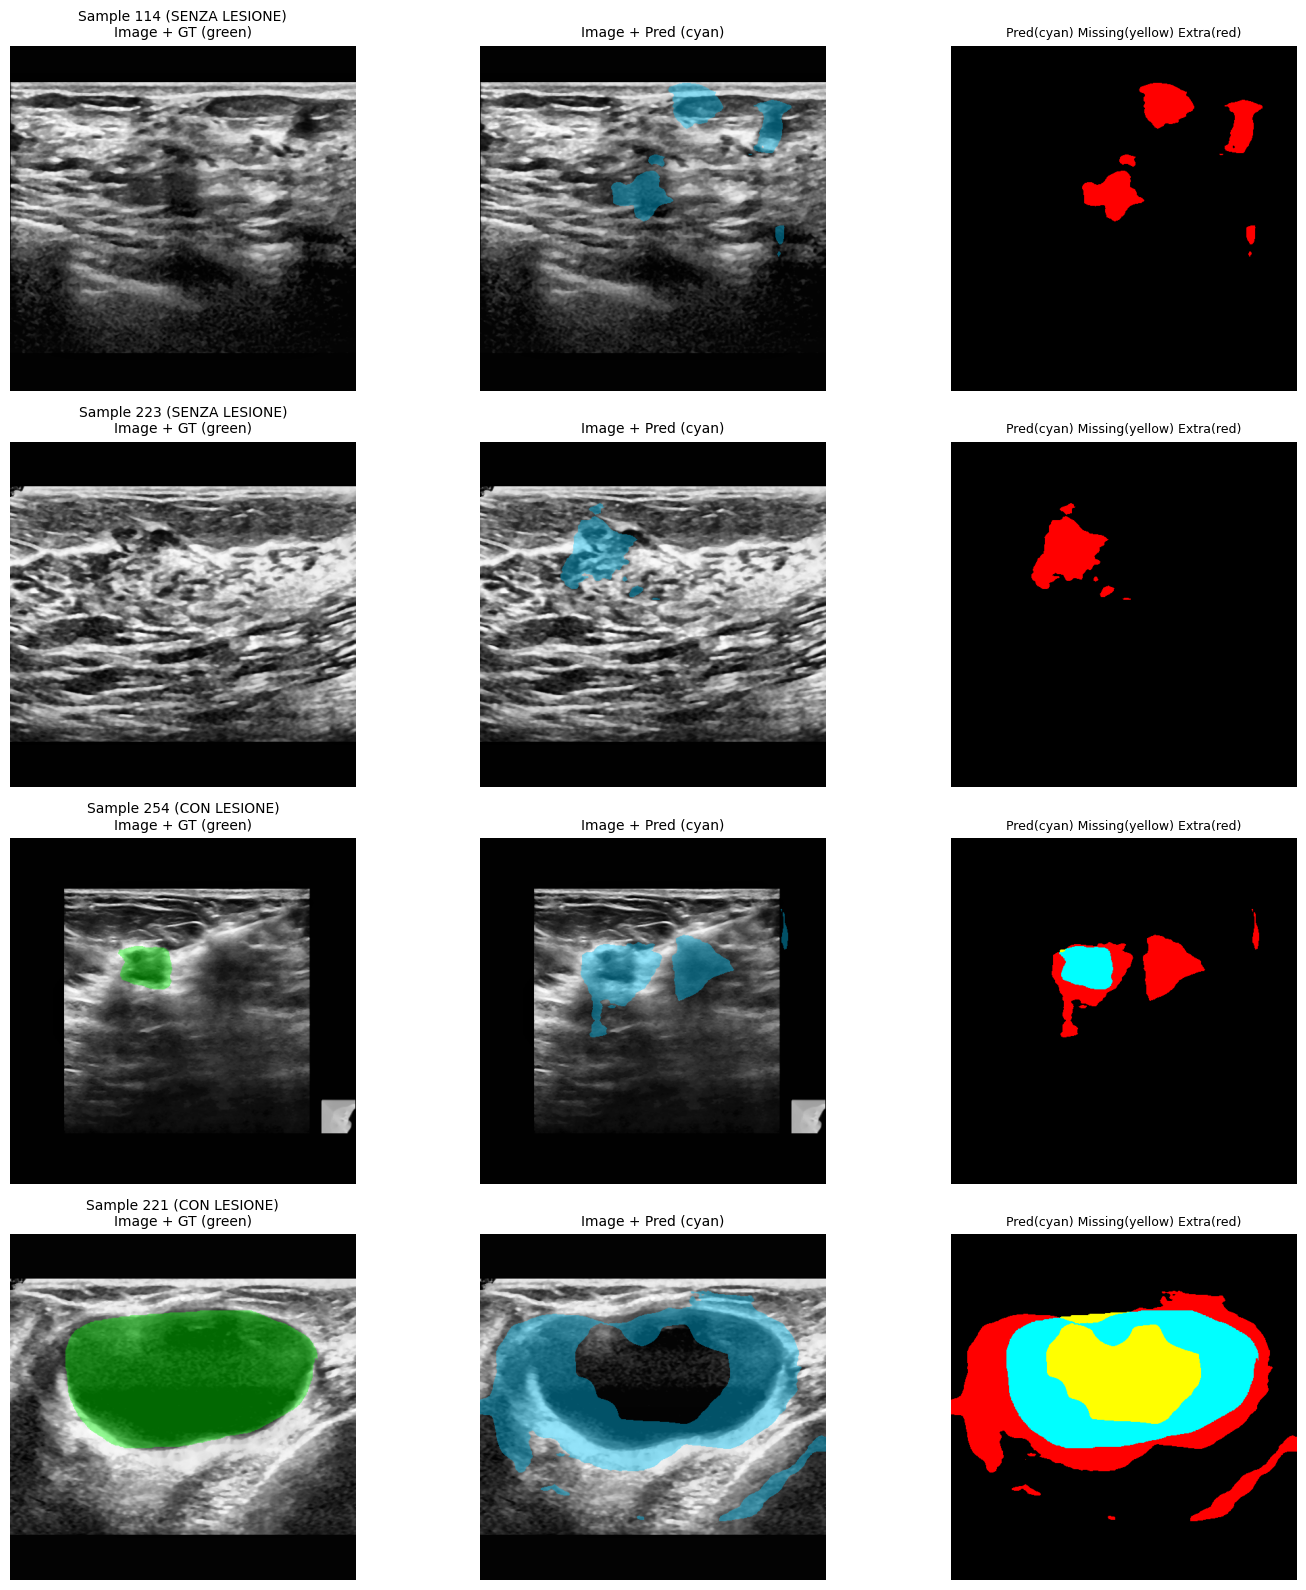

✅ Best model saved! Dice: 0.4571


Train 6:   0%|          | 0/293 [00:00<?, ?it/s]

Val:   0%|          | 0/106 [00:00<?, ?it/s]


📊 Epoch 6/60 ⏳ Warm-up (no gating) | LR: 1.45e-05
Train Loss: 6.2321 | Det Acc: 0.7053
Val Loss: 4.7902 | Det Acc: 0.6772
Val Dice: 0.5140 | Recall: 0.7059 | Precision: 0.4041
✅ Best model saved! Dice: 0.5140


Train 7:   0%|          | 0/293 [00:00<?, ?it/s]

...

Val:   0%|          | 0/106 [00:00<?, ?it/s]


📊 Epoch 9/60 ⏳ Warm-up (no gating) | LR: 1.95e-06
Train Loss: 5.6688 | Det Acc: 0.7053
Val Loss: 4.3680 | Det Acc: 0.6772
Val Dice: 0.5903 | Recall: 0.7225 | Precision: 0.4990
✅ Best model saved! Dice: 0.5903


Train 10:   0%|          | 0/293 [00:00<?, ?it/s]

Val:   0%|          | 0/106 [00:00<?, ?it/s]


📊 Epoch 10/60 ⏳ Warm-up (no gating) | LR: 4.00e-05
Train Loss: 5.6111 | Det Acc: 0.7053
Val Loss: 4.2957 | Det Acc: 0.6772
Val Dice: 0.6062 | Recall: 0.7310 | Precision: 0.5177

🎨 Visualization epoch 10 (campioni fissi)...


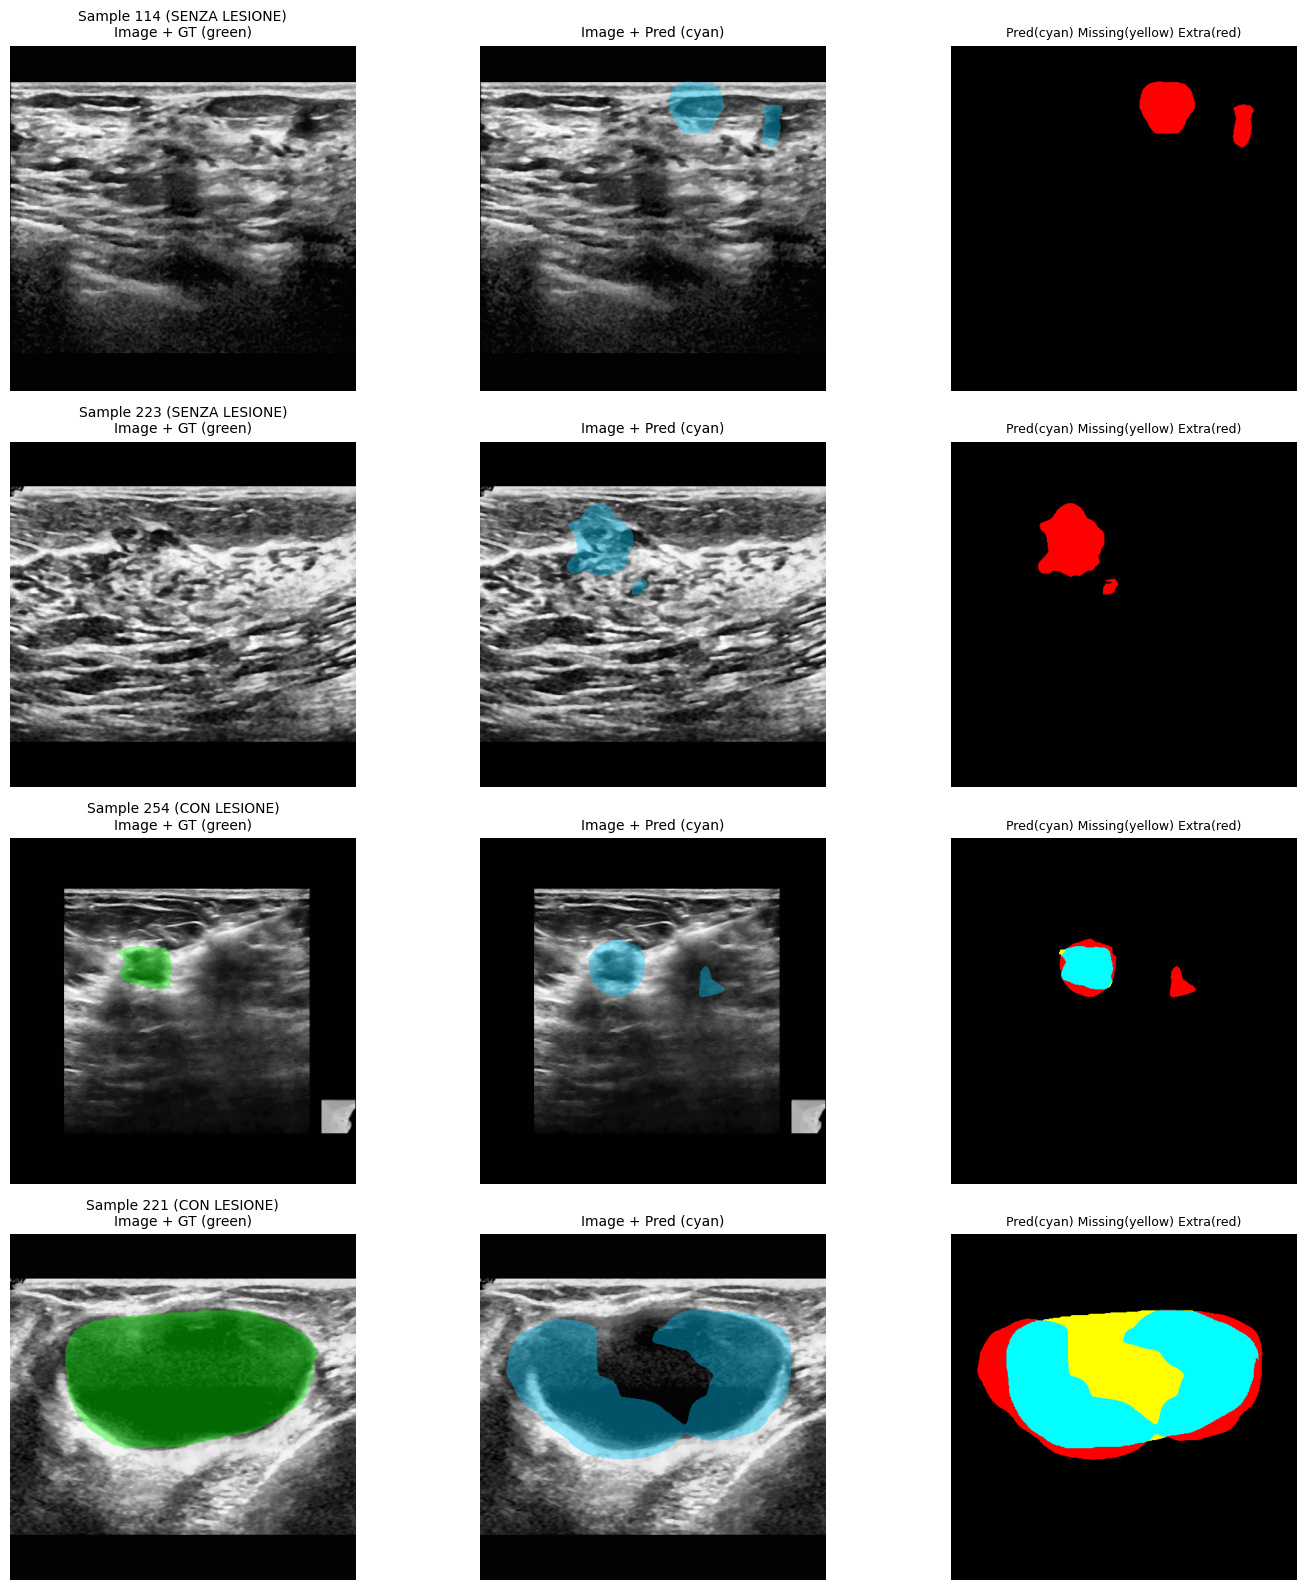

✅ Best model saved! Dice: 0.6062


Train 11:   0%|          | 0/293 [00:00<?, ?it/s]

Val:   0%|          | 0/106 [00:00<?, ?it/s]


📊 Epoch 11/60 🔒 GATING ATTIVO | LR: 3.98e-05
Train Loss: 5.3383 | Det Acc: 0.7042
Val Loss: 3.9827 | Det Acc: 0.6772
Val Dice: 0.0000 | Recall: 0.0000 | Precision: 0.0000


Train 12:   0%|          | 0/293 [00:00<?, ?it/s]

...

Val:   0%|          | 0/106 [00:00<?, ?it/s]


📊 Epoch 14/60 🔒 GATING ATTIVO | LR: 3.63e-05
Train Loss: 4.2786 | Det Acc: 0.7053
Val Loss: 3.1890 | Det Acc: 0.6772
Val Dice: 0.5175 | Recall: 0.4854 | Precision: 0.5541


Train 15:   0%|          | 0/293 [00:00<?, ?it/s]

Val:   0%|          | 0/106 [00:00<?, ?it/s]


📊 Epoch 15/60 🔒 GATING ATTIVO | LR: 3.43e-05
Train Loss: 4.0222 | Det Acc: 0.7053
Val Loss: 2.9998 | Det Acc: 0.6772
Val Dice: 0.6146 | Recall: 0.4999 | Precision: 0.7977

🎨 Visualization epoch 15 (campioni fissi)...


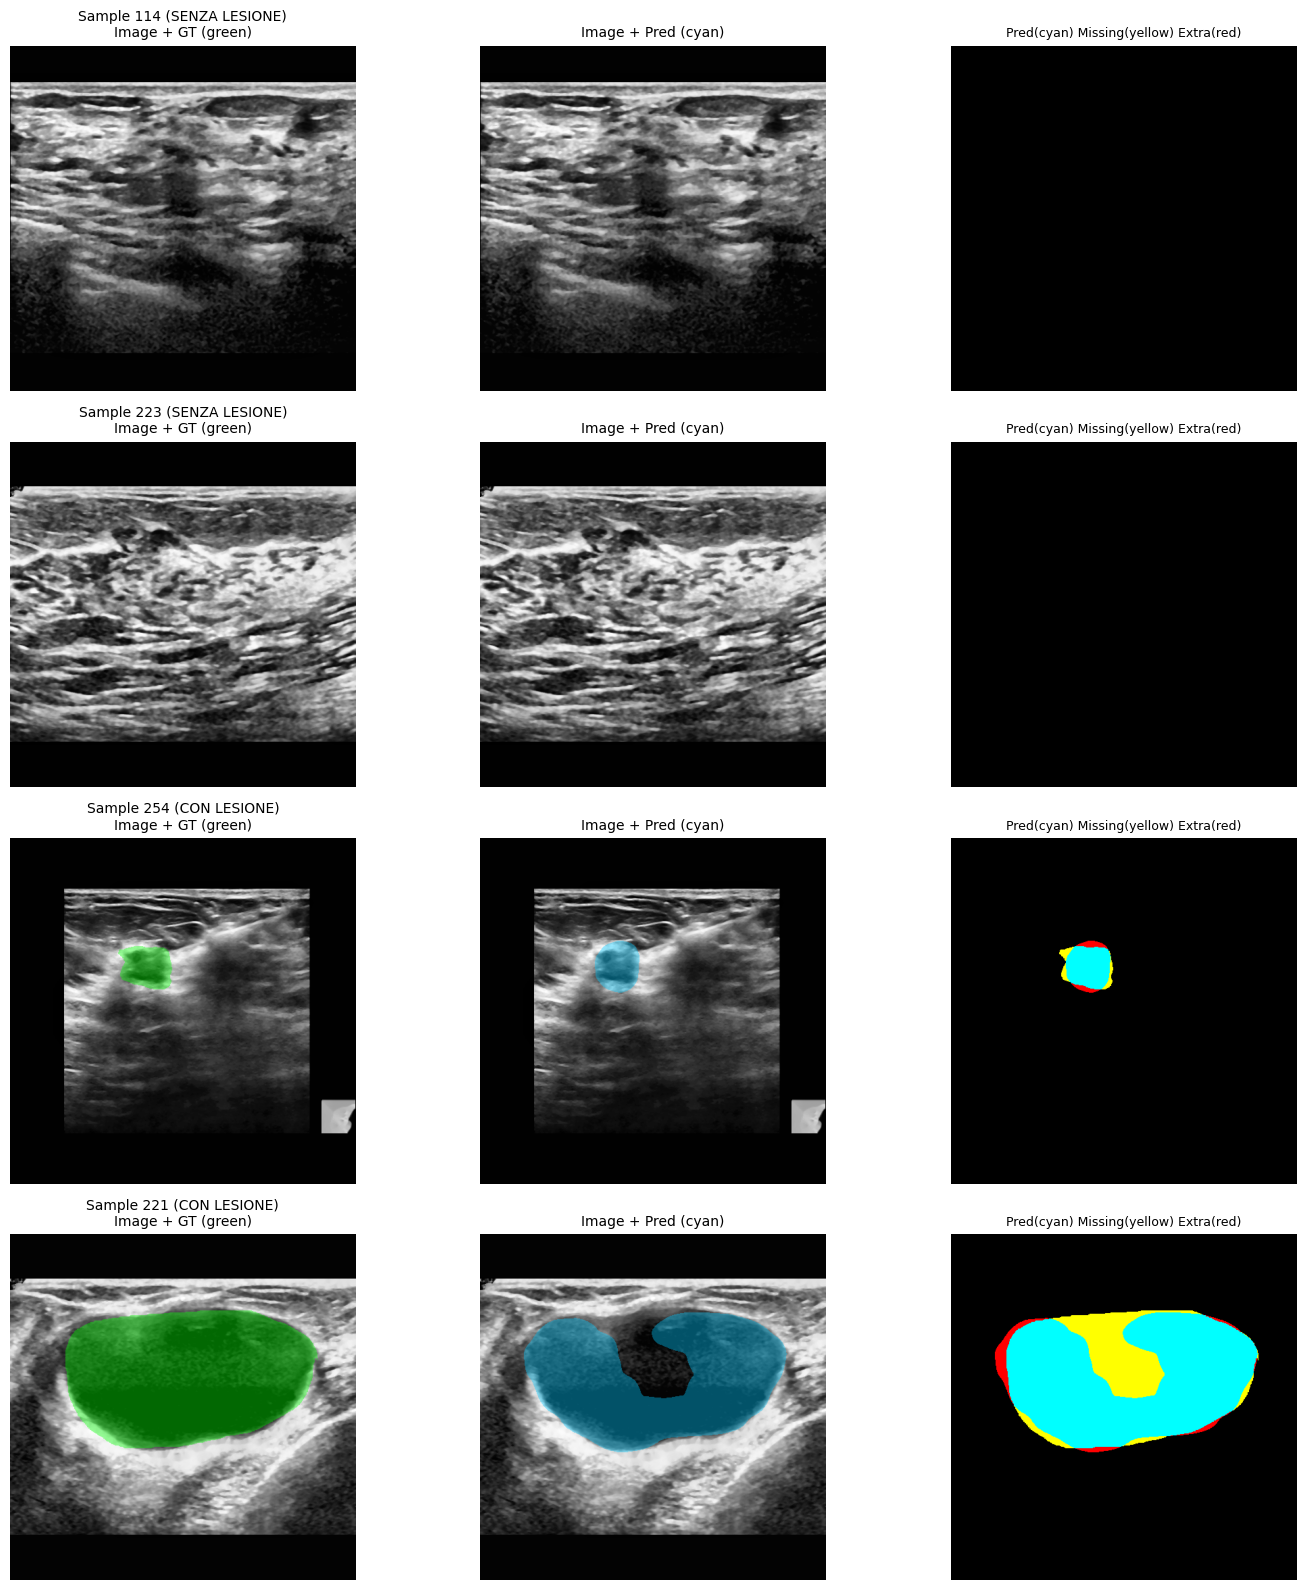

✅ Best model saved! Dice: 0.6146


Train 16:   0%|          | 0/293 [00:00<?, ?it/s]

Val:   0%|          | 0/106 [00:00<?, ?it/s]


📊 Epoch 16/60 🔒 GATING ATTIVO | LR: 3.20e-05
Train Loss: 3.8027 | Det Acc: 0.7053
Val Loss: 2.8703 | Det Acc: 0.6646
Val Dice: 0.5160 | Recall: 0.4957 | Precision: 0.5379


Train 17:   0%|          | 0/293 [00:00<?, ?it/s]

...

Val:   0%|          | 0/106 [00:00<?, ?it/s]


📊 Epoch 19/60 🔒 GATING ATTIVO | LR: 2.36e-05
Train Loss: 3.4856 | Det Acc: 0.7053
Val Loss: 2.5962 | Det Acc: 0.6741
Val Dice: 0.6626 | Recall: 0.6034 | Precision: 0.7348
✅ Best model saved! Dice: 0.6626


Train 20:   0%|          | 0/293 [00:00<?, ?it/s]

Val:   0%|          | 0/106 [00:00<?, ?it/s]


📊 Epoch 20/60 🔒 GATING ATTIVO | LR: 2.05e-05
Train Loss: 3.4099 | Det Acc: 0.7053
Val Loss: 2.5045 | Det Acc: 0.6646
Val Dice: 0.6257 | Recall: 0.6098 | Precision: 0.6424

🎨 Visualization epoch 20 (campioni fissi)...


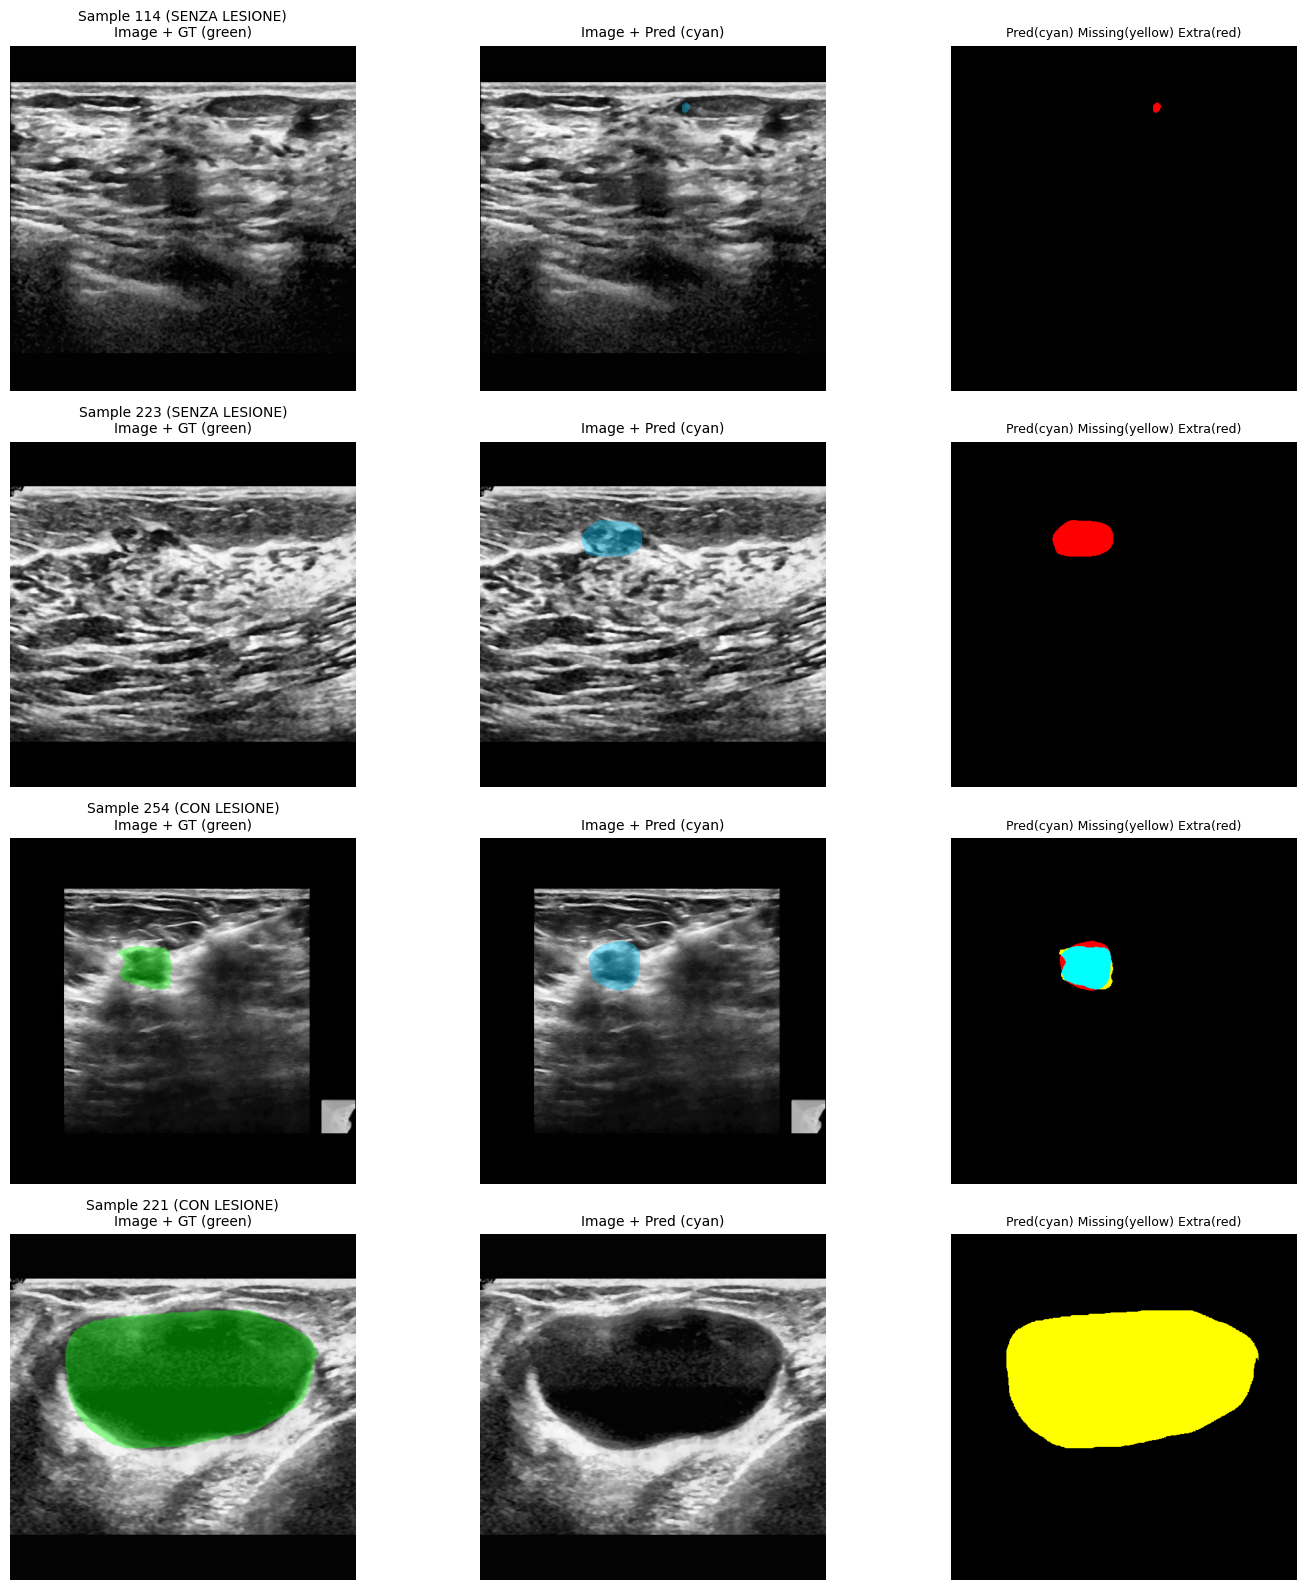

Train 21:   0%|          | 0/293 [00:00<?, ?it/s]

Val:   0%|          | 0/106 [00:00<?, ?it/s]


📊 Epoch 21/60 🔒 GATING ATTIVO | LR: 1.74e-05
Train Loss: 3.3079 | Det Acc: 0.7053
Val Loss: 2.5075 | Det Acc: 0.6741
Val Dice: 0.6701 | Recall: 0.6297 | Precision: 0.7161
✅ Best model saved! Dice: 0.6701


Train 22:   0%|          | 0/293 [00:00<?, ?it/s]

Val:   0%|          | 0/106 [00:00<?, ?it/s]

...

Val:   0%|          | 0/106 [00:00<?, ?it/s]


📊 Epoch 24/60 🔒 GATING ATTIVO | LR: 9.04e-06
Train Loss: 3.1723 | Det Acc: 0.7053
Val Loss: 2.4754 | Det Acc: 0.6772
Val Dice: 0.7222 | Recall: 0.7516 | Precision: 0.6951


Train 25:   0%|          | 0/293 [00:00<?, ?it/s]

Val:   0%|          | 0/106 [00:00<?, ?it/s]


📊 Epoch 25/60 🔒 GATING ATTIVO | LR: 6.71e-06
Train Loss: 3.1153 | Det Acc: 0.7053
Val Loss: 2.5197 | Det Acc: 0.6772
Val Dice: 0.7327 | Recall: 0.7382 | Precision: 0.7272

🎨 Visualization epoch 25 (campioni fissi)...


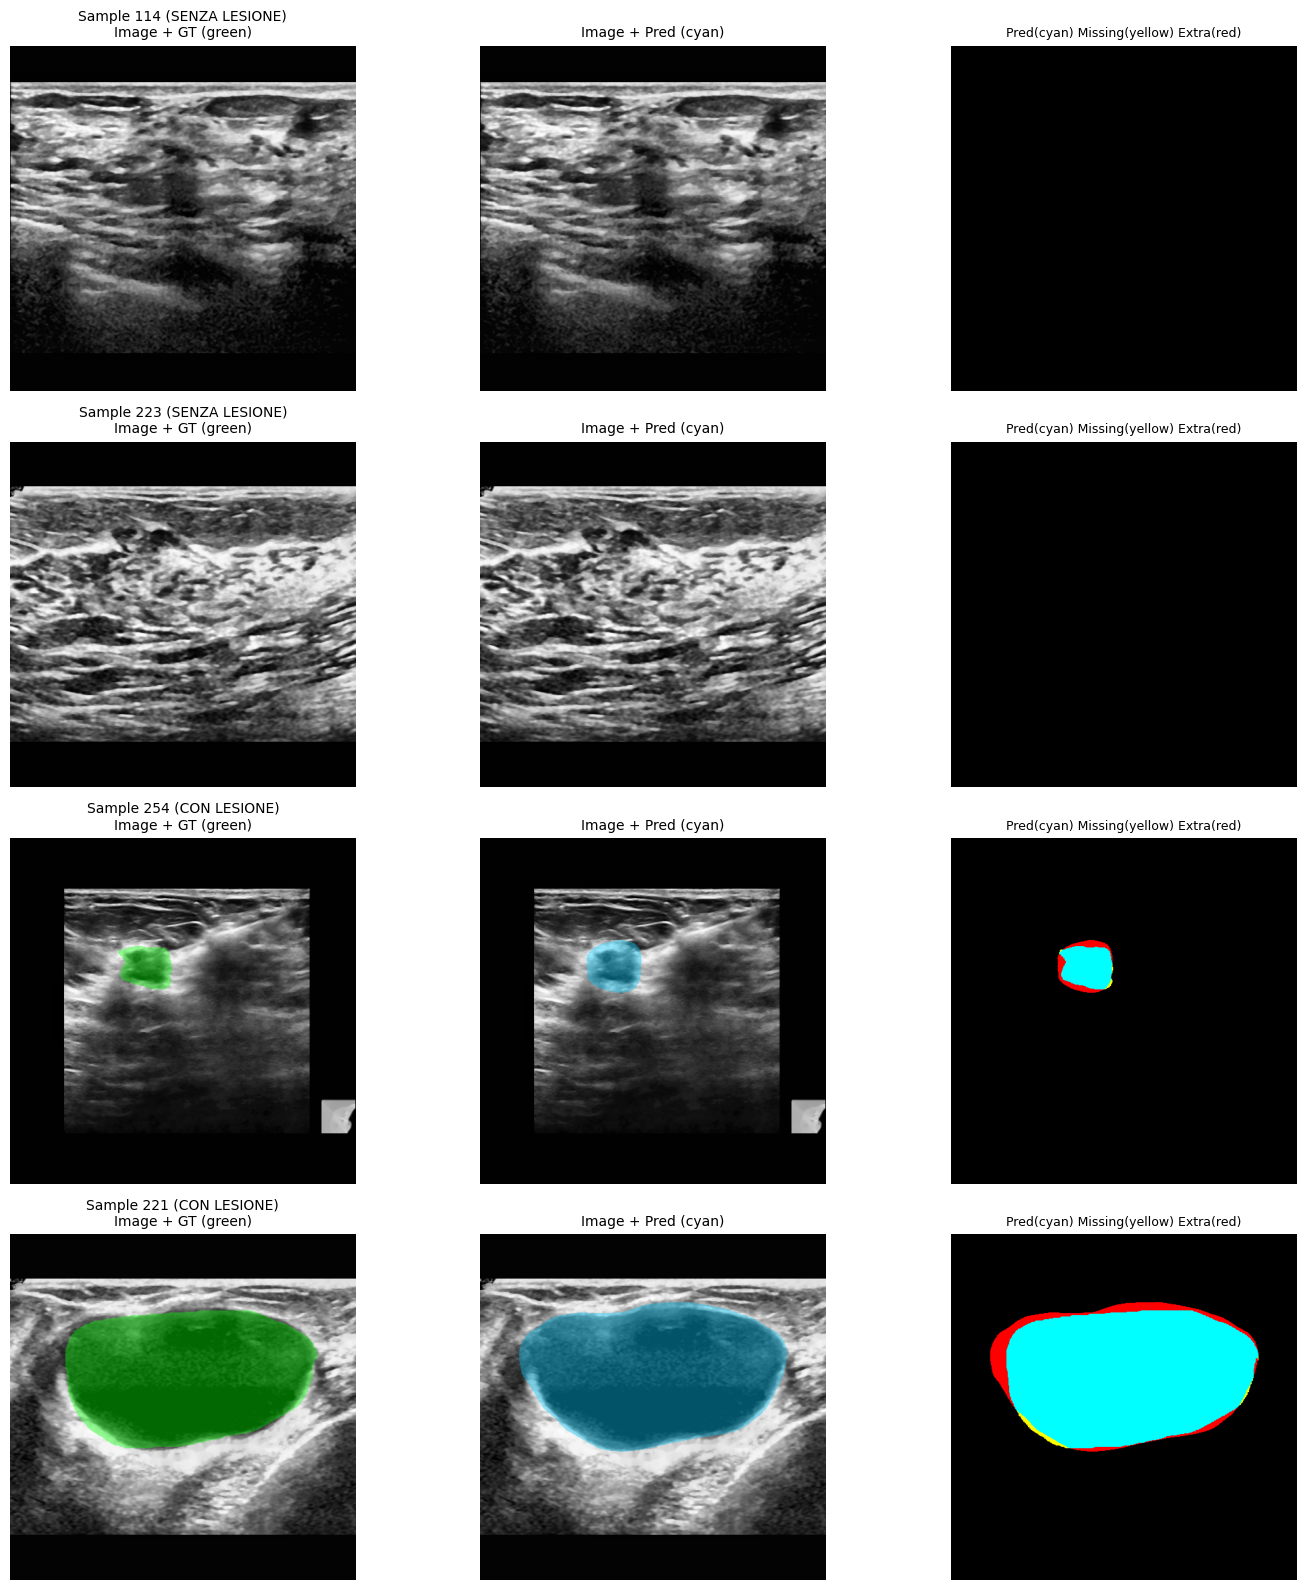

✅ Best model saved! Dice: 0.7327


Train 26:   0%|          | 0/293 [00:00<?, ?it/s]

Val:   0%|          | 0/106 [00:00<?, ?it/s]


📊 Epoch 26/60 🔒 GATING ATTIVO | LR: 4.72e-06
Train Loss: 3.1480 | Det Acc: 0.7053
Val Loss: 2.4481 | Det Acc: 0.6741
Val Dice: 0.7049 | Recall: 0.7777 | Precision: 0.6445


Train 27:   0%|          | 0/293 [00:00<?, ?it/s]

...

Val:   0%|          | 0/106 [00:00<?, ?it/s]


📊 Epoch 29/60 🔒 GATING ATTIVO | LR: 1.24e-06
Train Loss: 3.1797 | Det Acc: 0.7053
Val Loss: 2.3745 | Det Acc: 0.6772
Val Dice: 0.7316 | Recall: 0.7906 | Precision: 0.6808


Train 30:   0%|          | 0/293 [00:00<?, ?it/s]

Val:   0%|          | 0/106 [00:00<?, ?it/s]


📊 Epoch 30/60 🔒 GATING ATTIVO | LR: 4.00e-05
Train Loss: 3.0748 | Det Acc: 0.7053
Val Loss: 2.3744 | Det Acc: 0.6772
Val Dice: 0.7366 | Recall: 0.7801 | Precision: 0.6976

🎨 Visualization epoch 30 (campioni fissi)...


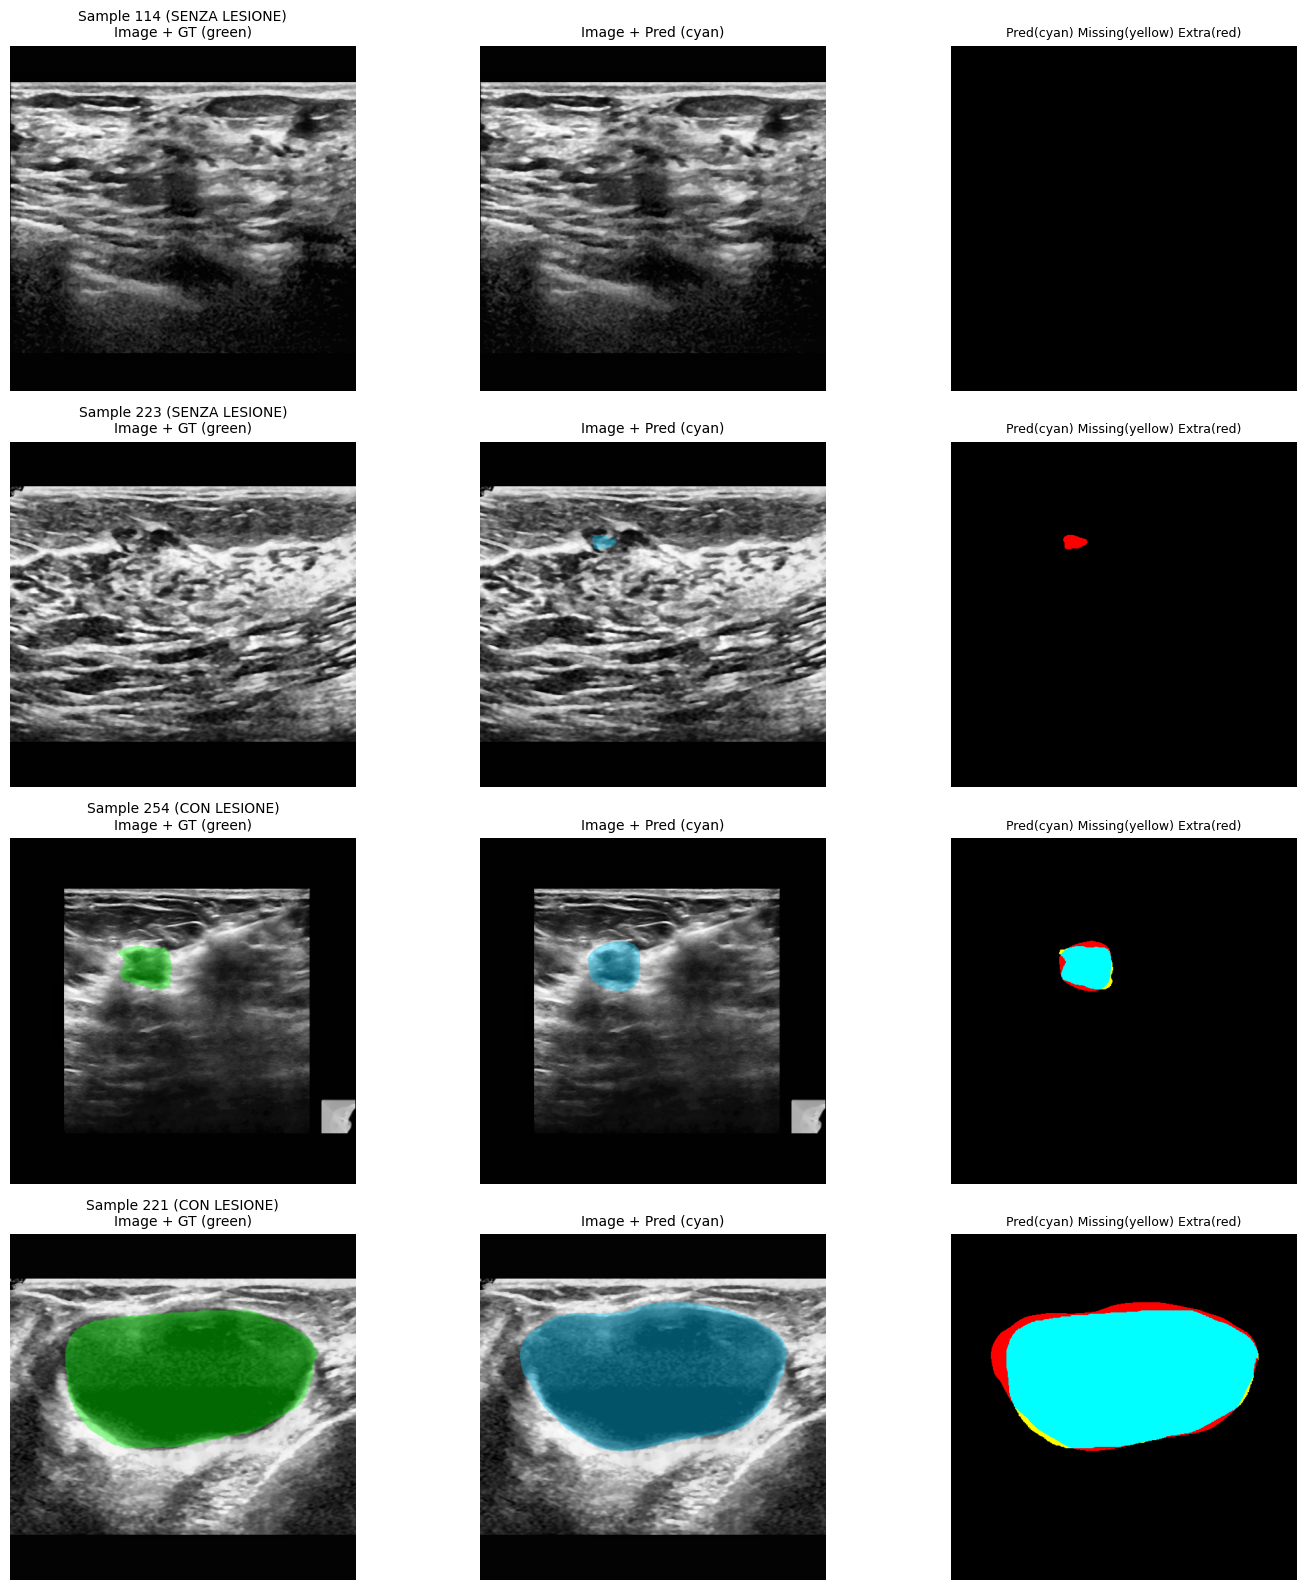

Train 31:   0%|          | 0/293 [00:00<?, ?it/s]

Val:   0%|          | 0/106 [00:00<?, ?it/s]


📊 Epoch 31/60 🔒 GATING ATTIVO | LR: 3.99e-05
Train Loss: 3.1755 | Det Acc: 0.7053
Val Loss: 2.3871 | Det Acc: 0.6772
Val Dice: 0.7218 | Recall: 0.8417 | Precision: 0.6319


Train 32:   0%|          | 0/293 [00:00<?, ?it/s]

Val:   0%|          | 0/106 [00:00<?, ?it/s]

...

Val:   0%|          | 0/106 [00:00<?, ?it/s]


📊 Epoch 34/60 🔒 GATING ATTIVO | LR: 3.90e-05
Train Loss: 3.0331 | Det Acc: 0.7053
Val Loss: 2.4968 | Det Acc: 0.6772
Val Dice: 0.7369 | Recall: 0.8099 | Precision: 0.6761


Train 35:   0%|          | 0/293 [00:00<?, ?it/s]

Val:   0%|          | 0/106 [00:00<?, ?it/s]


📊 Epoch 35/60 🔒 GATING ATTIVO | LR: 3.85e-05
Train Loss: 2.8978 | Det Acc: 0.7053
Val Loss: 2.2638 | Det Acc: 0.6772
Val Dice: 0.7355 | Recall: 0.8540 | Precision: 0.6460

🎨 Visualization epoch 35 (campioni fissi)...


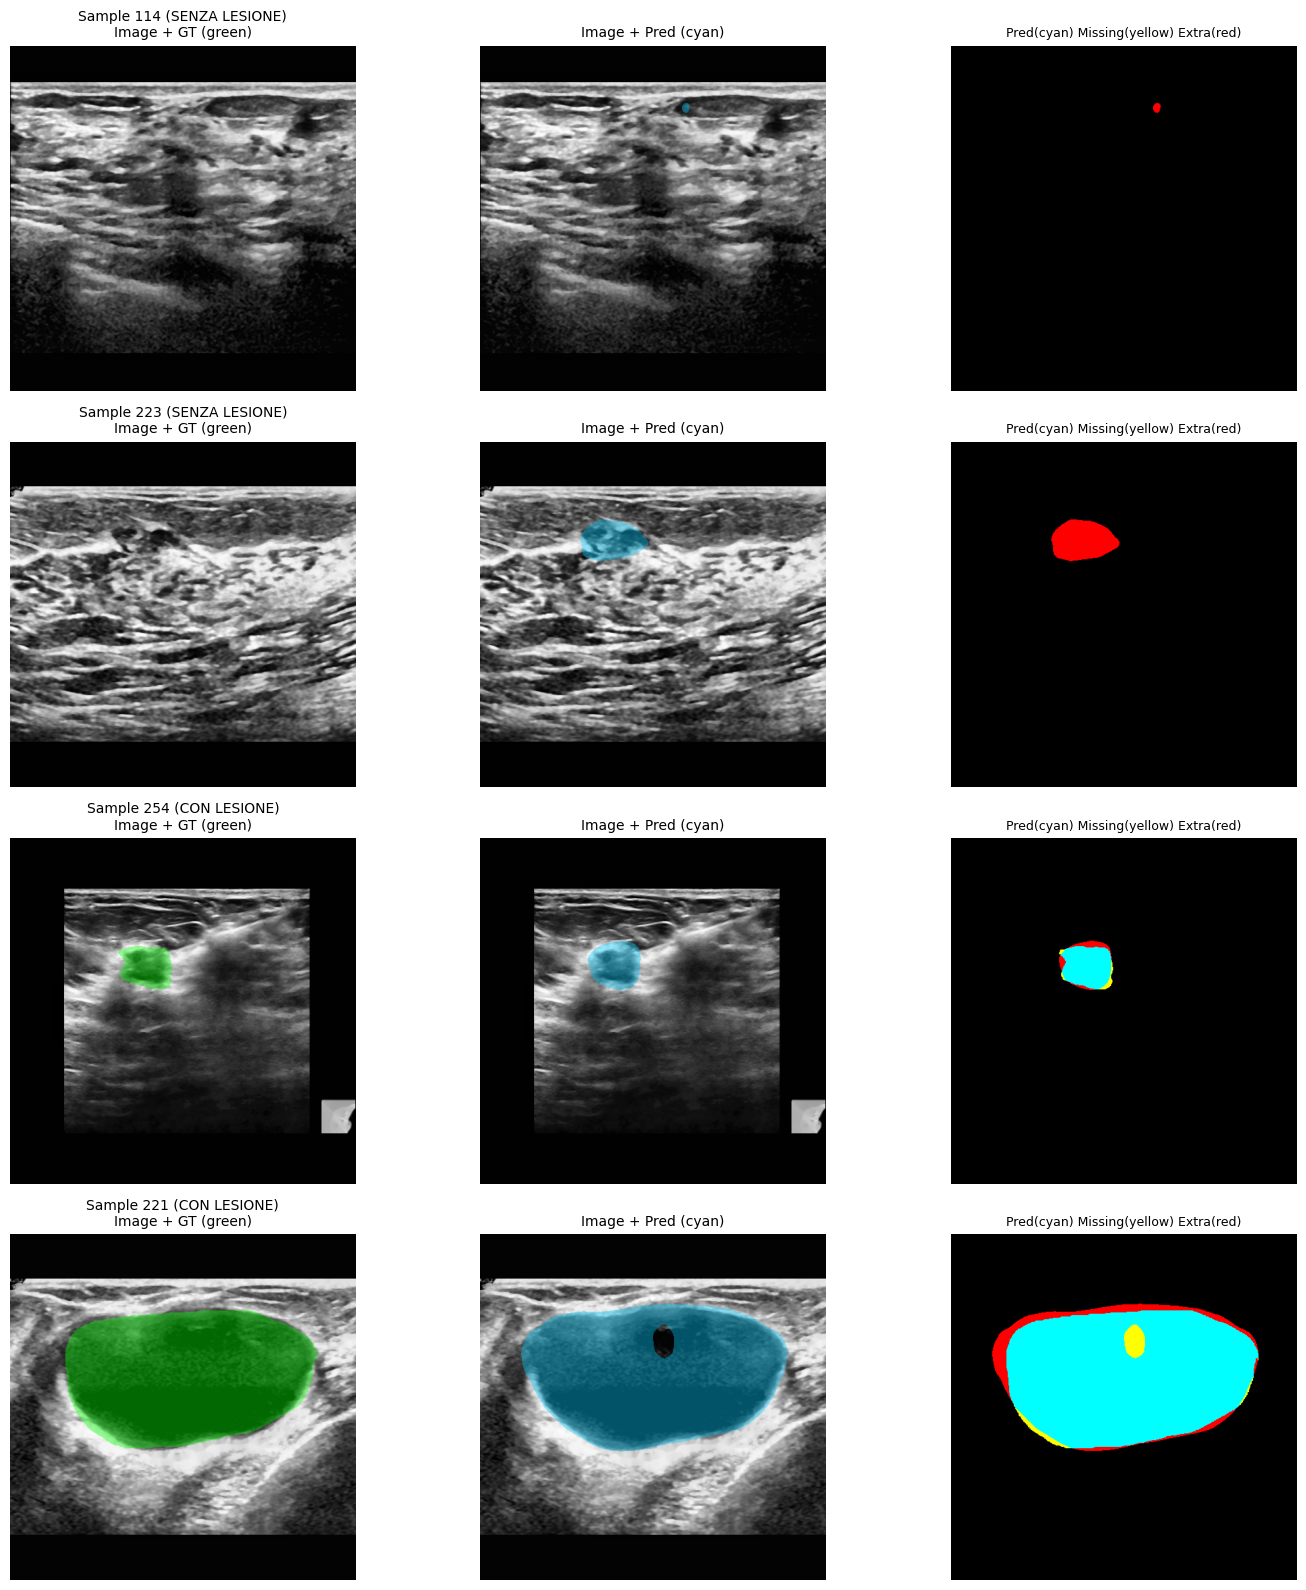

Train 36:   0%|          | 0/293 [00:00<?, ?it/s]

Val:   0%|          | 0/106 [00:00<?, ?it/s]


📊 Epoch 36/60 🔒 GATING ATTIVO | LR: 3.79e-05
Train Loss: 2.8483 | Det Acc: 0.7053
Val Loss: 2.2930 | Det Acc: 0.6772
Val Dice: 0.6928 | Recall: 0.8610 | Precision: 0.5796


Train 37:   0%|          | 0/293 [00:00<?, ?it/s]

Val:   0%|          | 0/106 [00:00<?, ?it/s]

...

Val:   0%|          | 0/106 [00:00<?, ?it/s]


📊 Epoch 39/60 🔒 GATING ATTIVO | LR: 3.53e-05
Train Loss: 2.5955 | Det Acc: 0.7383
Val Loss: 2.0607 | Det Acc: 0.8892
Val Dice: 0.7647 | Recall: 0.7532 | Precision: 0.7765
✅ Best model saved! Dice: 0.7647


Train 40:   0%|          | 0/293 [00:00<?, ?it/s]

Val:   0%|          | 0/106 [00:00<?, ?it/s]


📊 Epoch 40/60 🔒 GATING ATTIVO | LR: 3.43e-05
Train Loss: 2.3937 | Det Acc: 0.7929
Val Loss: 1.9608 | Det Acc: 0.8956
Val Dice: 0.7618 | Recall: 0.8056 | Precision: 0.7225

🎨 Visualization epoch 40 (campioni fissi)...


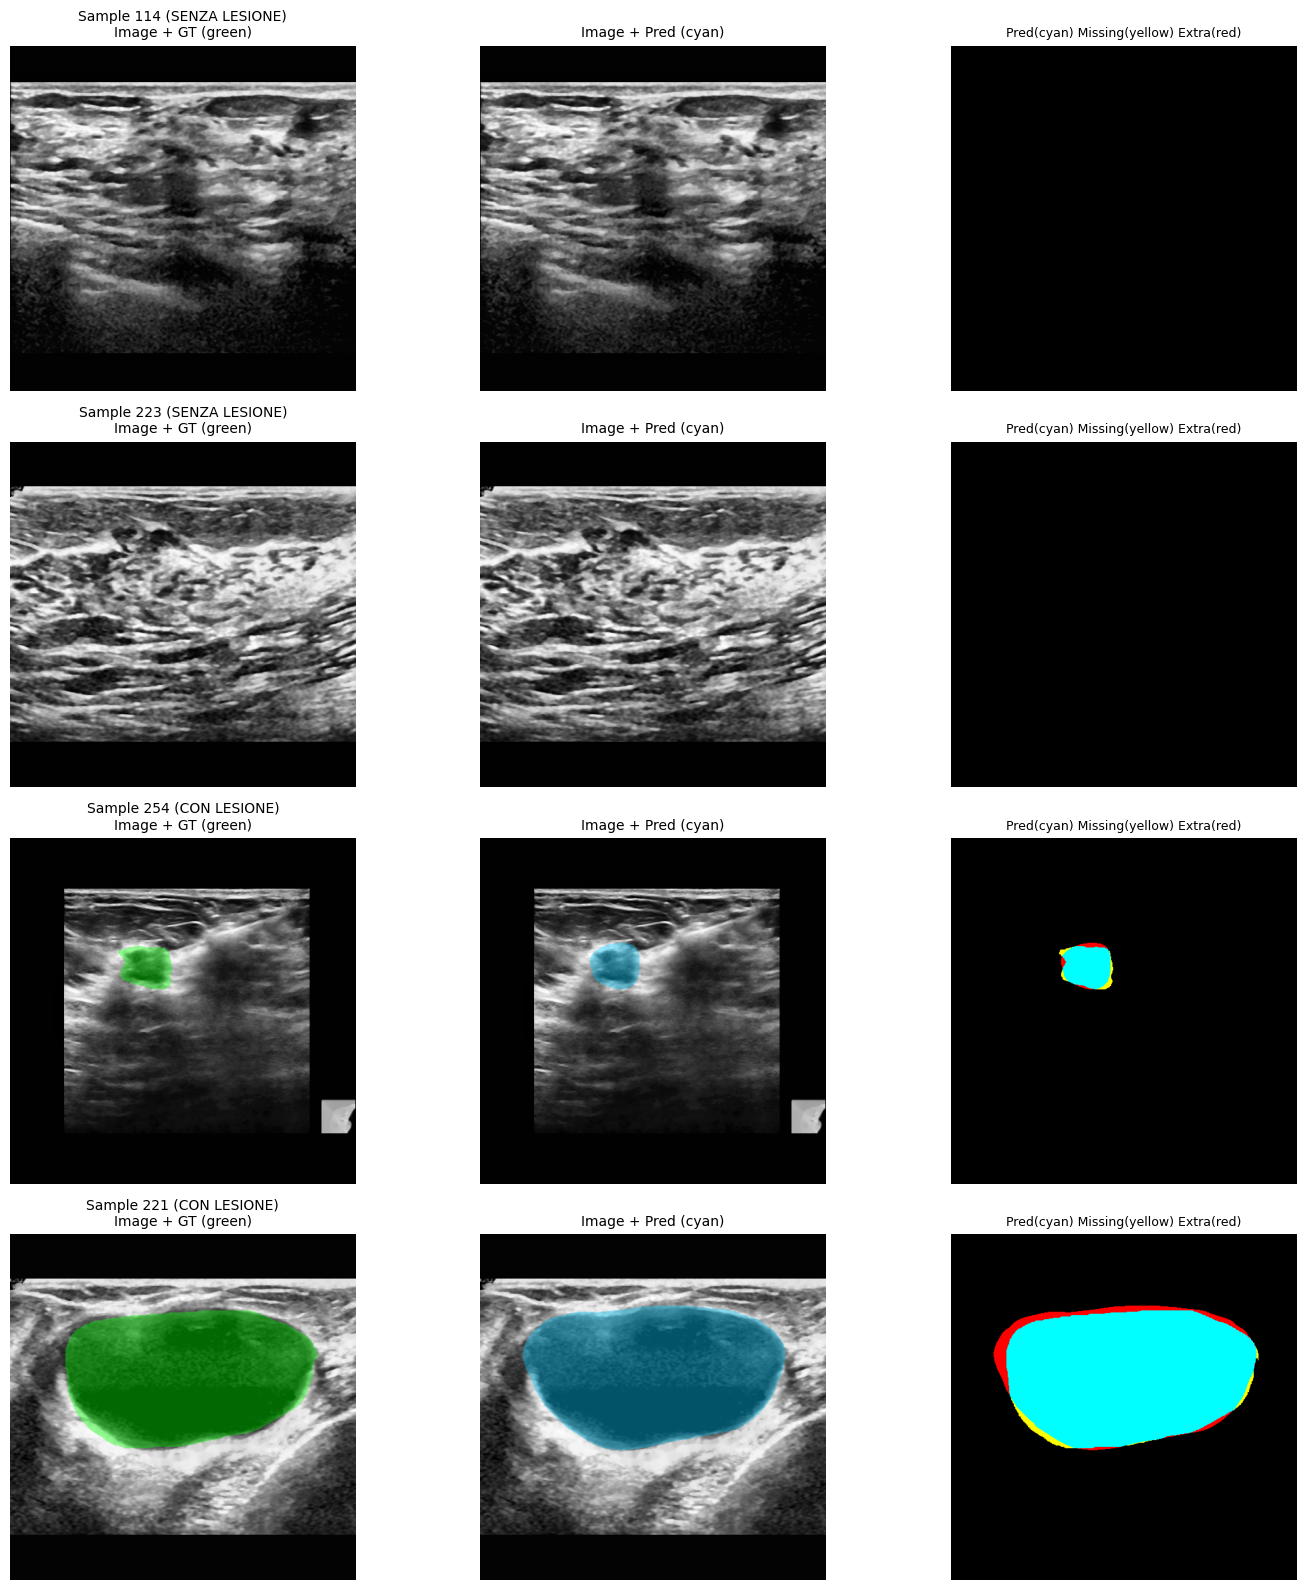

Train 41:   0%|          | 0/293 [00:00<?, ?it/s]

Val:   0%|          | 0/106 [00:00<?, ?it/s]


📊 Epoch 41/60 🔒 GATING ATTIVO | LR: 3.32e-05
Train Loss: 2.3680 | Det Acc: 0.8396
Val Loss: 2.0120 | Det Acc: 0.8924
Val Dice: 0.7680 | Recall: 0.7697 | Precision: 0.7662
✅ Best model saved! Dice: 0.7680


Train 42:   0%|          | 0/293 [00:00<?, ?it/s]

Val:   0%|          | 0/106 [00:00<?, ?it/s]

...

Val:   0%|          | 0/106 [00:00<?, ?it/s]


📊 Epoch 44/60 🔒 GATING ATTIVO | LR: 2.94e-05
Train Loss: 2.1828 | Det Acc: 0.8942
Val Loss: 1.8952 | Det Acc: 0.8956
Val Dice: 0.7592 | Recall: 0.7500 | Precision: 0.7687


Train 45:   0%|          | 0/293 [00:00<?, ?it/s]

Val:   0%|          | 0/106 [00:00<?, ?it/s]


📊 Epoch 45/60 🔒 GATING ATTIVO | LR: 2.80e-05
Train Loss: 2.1559 | Det Acc: 0.8919
Val Loss: 1.9549 | Det Acc: 0.8924
Val Dice: 0.7555 | Recall: 0.7880 | Precision: 0.7255

🎨 Visualization epoch 45 (campioni fissi)...


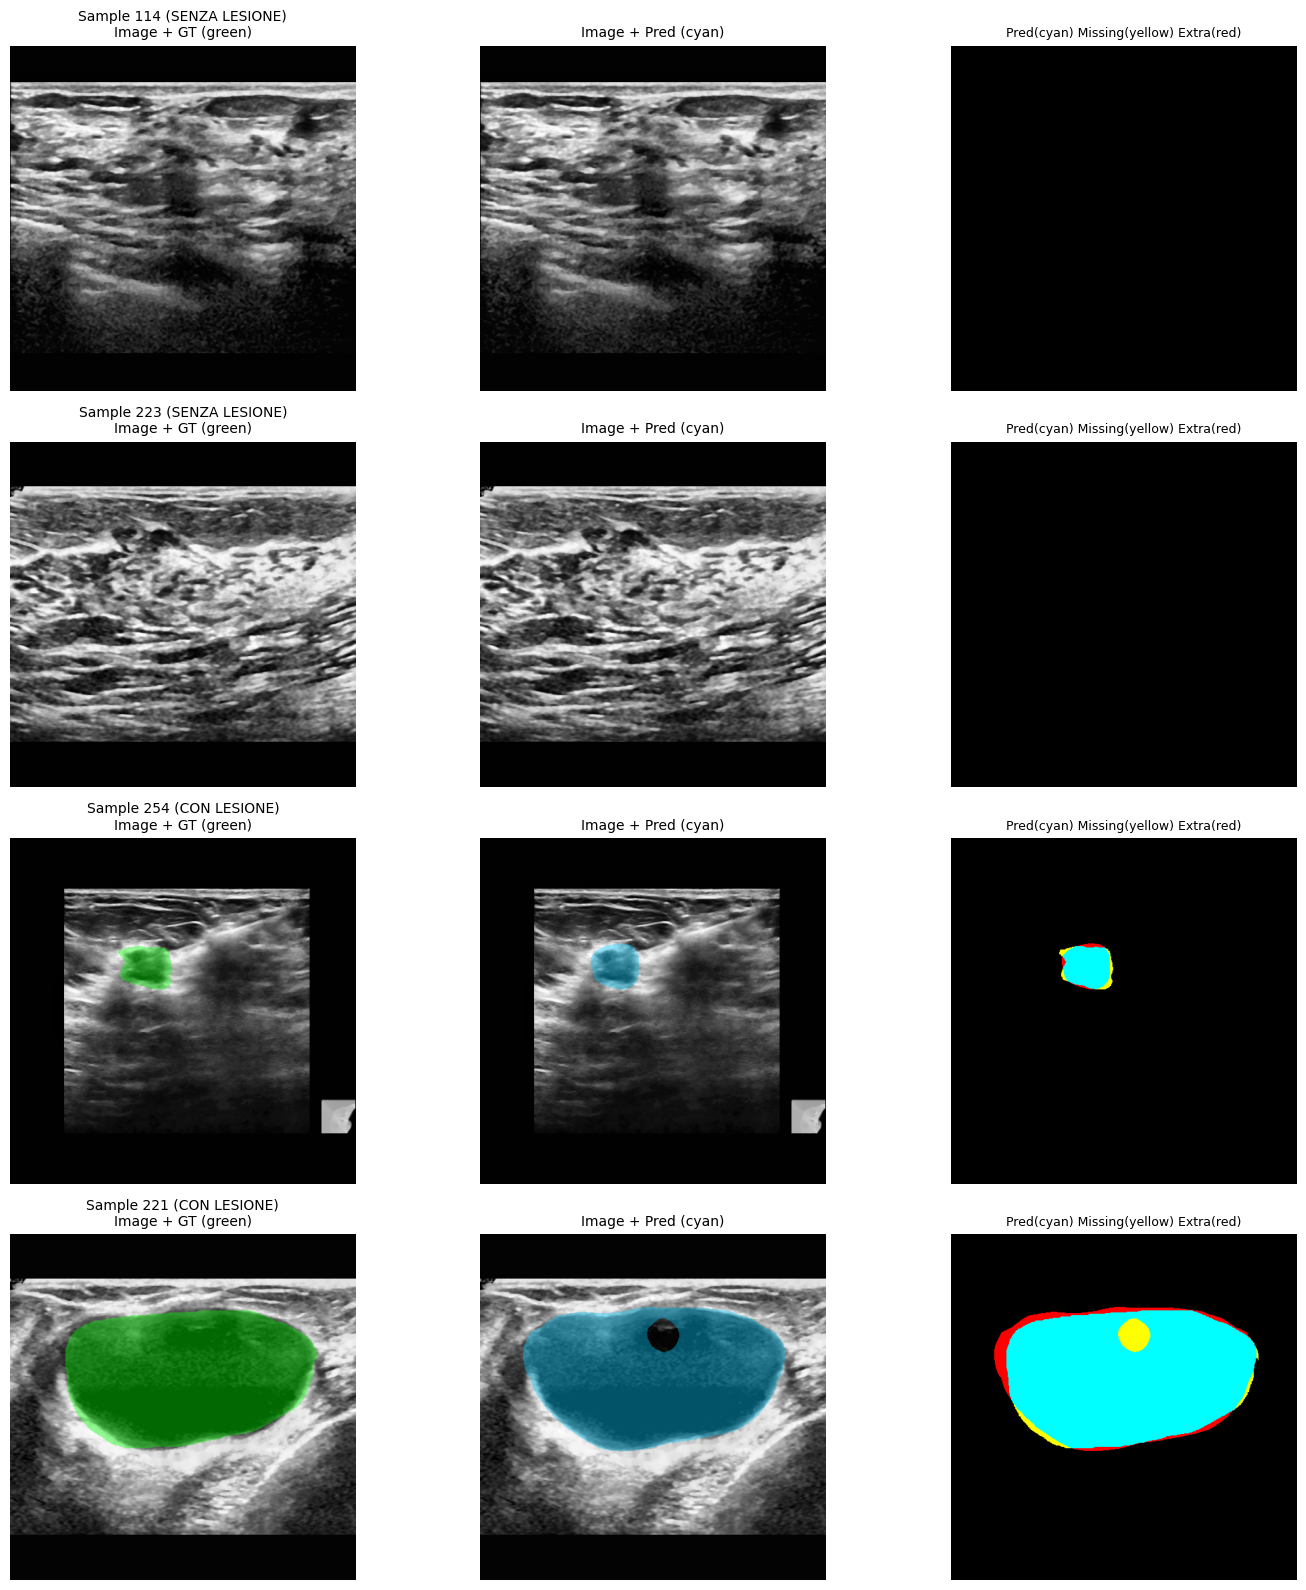

Train 46:   0%|          | 0/293 [00:00<?, ?it/s]

Val:   0%|          | 0/106 [00:00<?, ?it/s]


📊 Epoch 46/60 🔒 GATING ATTIVO | LR: 2.65e-05
Train Loss: 2.1148 | Det Acc: 0.9170
Val Loss: 1.9277 | Det Acc: 0.8987
Val Dice: 0.7502 | Recall: 0.8098 | Precision: 0.6988


Train 47:   0%|          | 0/293 [00:00<?, ?it/s]

Val:   0%|          | 0/106 [00:00<?, ?it/s]

...

Val:   0%|          | 0/106 [00:00<?, ?it/s]


📊 Epoch 49/60 🔒 GATING ATTIVO | LR: 2.20e-05
Train Loss: 1.9984 | Det Acc: 0.9067
Val Loss: 1.9995 | Det Acc: 0.9051
Val Dice: 0.7361 | Recall: 0.8185 | Precision: 0.6688


Train 50:   0%|          | 0/293 [00:00<?, ?it/s]

Val:   0%|          | 0/106 [00:00<?, ?it/s]


📊 Epoch 50/60 🔒 GATING ATTIVO | LR: 2.05e-05
Train Loss: 1.9126 | Det Acc: 0.9283
Val Loss: 1.9571 | Det Acc: 0.9051
Val Dice: 0.7408 | Recall: 0.8360 | Precision: 0.6650

🎨 Visualization epoch 50 (campioni fissi)...


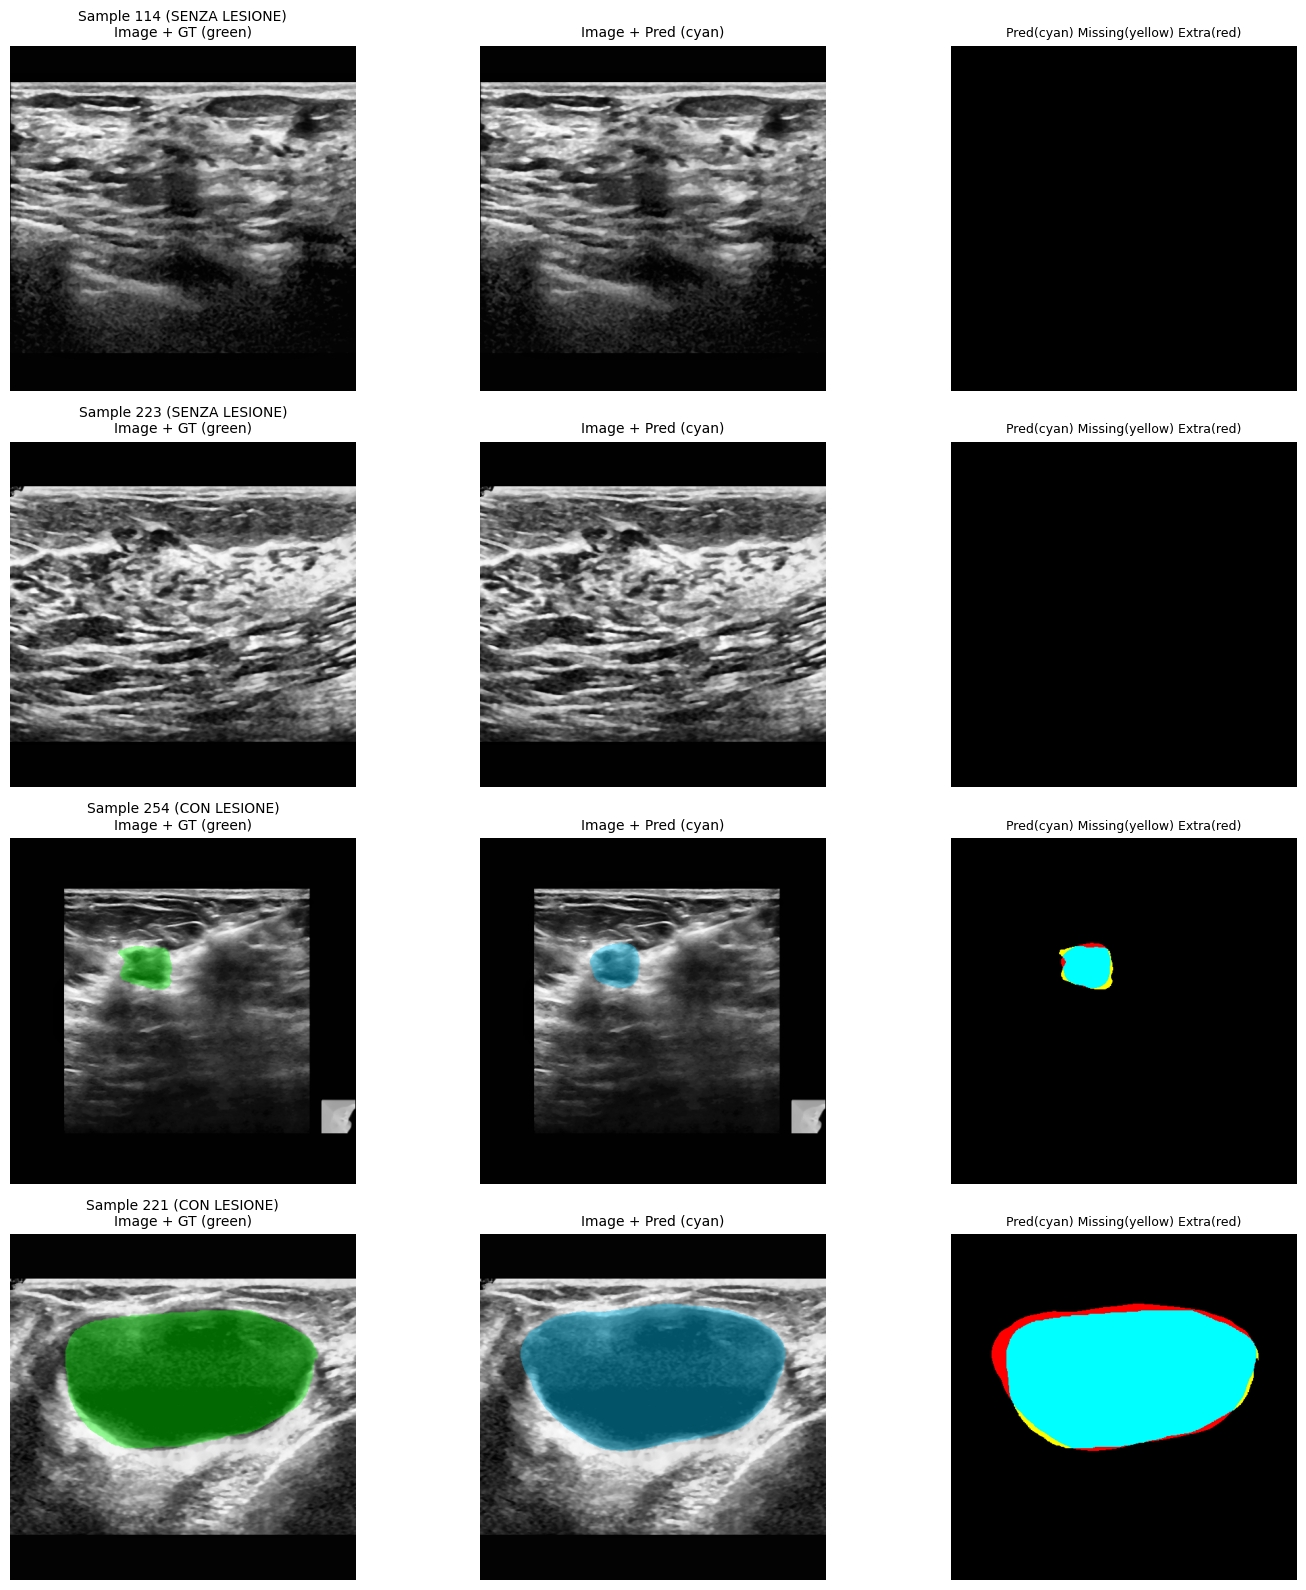

Train 51:   0%|          | 0/293 [00:00<?, ?it/s]

Val:   0%|          | 0/106 [00:00<?, ?it/s]


📊 Epoch 51/60 🔒 GATING ATTIVO | LR: 1.90e-05
Train Loss: 1.9629 | Det Acc: 0.9204
Val Loss: 1.9127 | Det Acc: 0.9114
Val Dice: 0.7607 | Recall: 0.7818 | Precision: 0.7408


Train 52:   0%|          | 0/293 [00:00<?, ?it/s]

Val:   0%|          | 0/106 [00:00<?, ?it/s]

...

Val:   0%|          | 0/106 [00:00<?, ?it/s]


📊 Epoch 54/60 🔒 GATING ATTIVO | LR: 1.45e-05
Train Loss: 1.8161 | Det Acc: 0.9261
Val Loss: 2.0852 | Det Acc: 0.9082
Val Dice: 0.7721 | Recall: 0.7877 | Precision: 0.7570
✅ Best model saved! Dice: 0.7721


Train 55:   0%|          | 0/293 [00:00<?, ?it/s]

Val:   0%|          | 0/106 [00:00<?, ?it/s]


📊 Epoch 55/60 🔒 GATING ATTIVO | LR: 1.30e-05
Train Loss: 1.8695 | Det Acc: 0.9329
Val Loss: 2.0915 | Det Acc: 0.9082
Val Dice: 0.7702 | Recall: 0.8023 | Precision: 0.7406

🎨 Visualization epoch 55 (campioni fissi)...


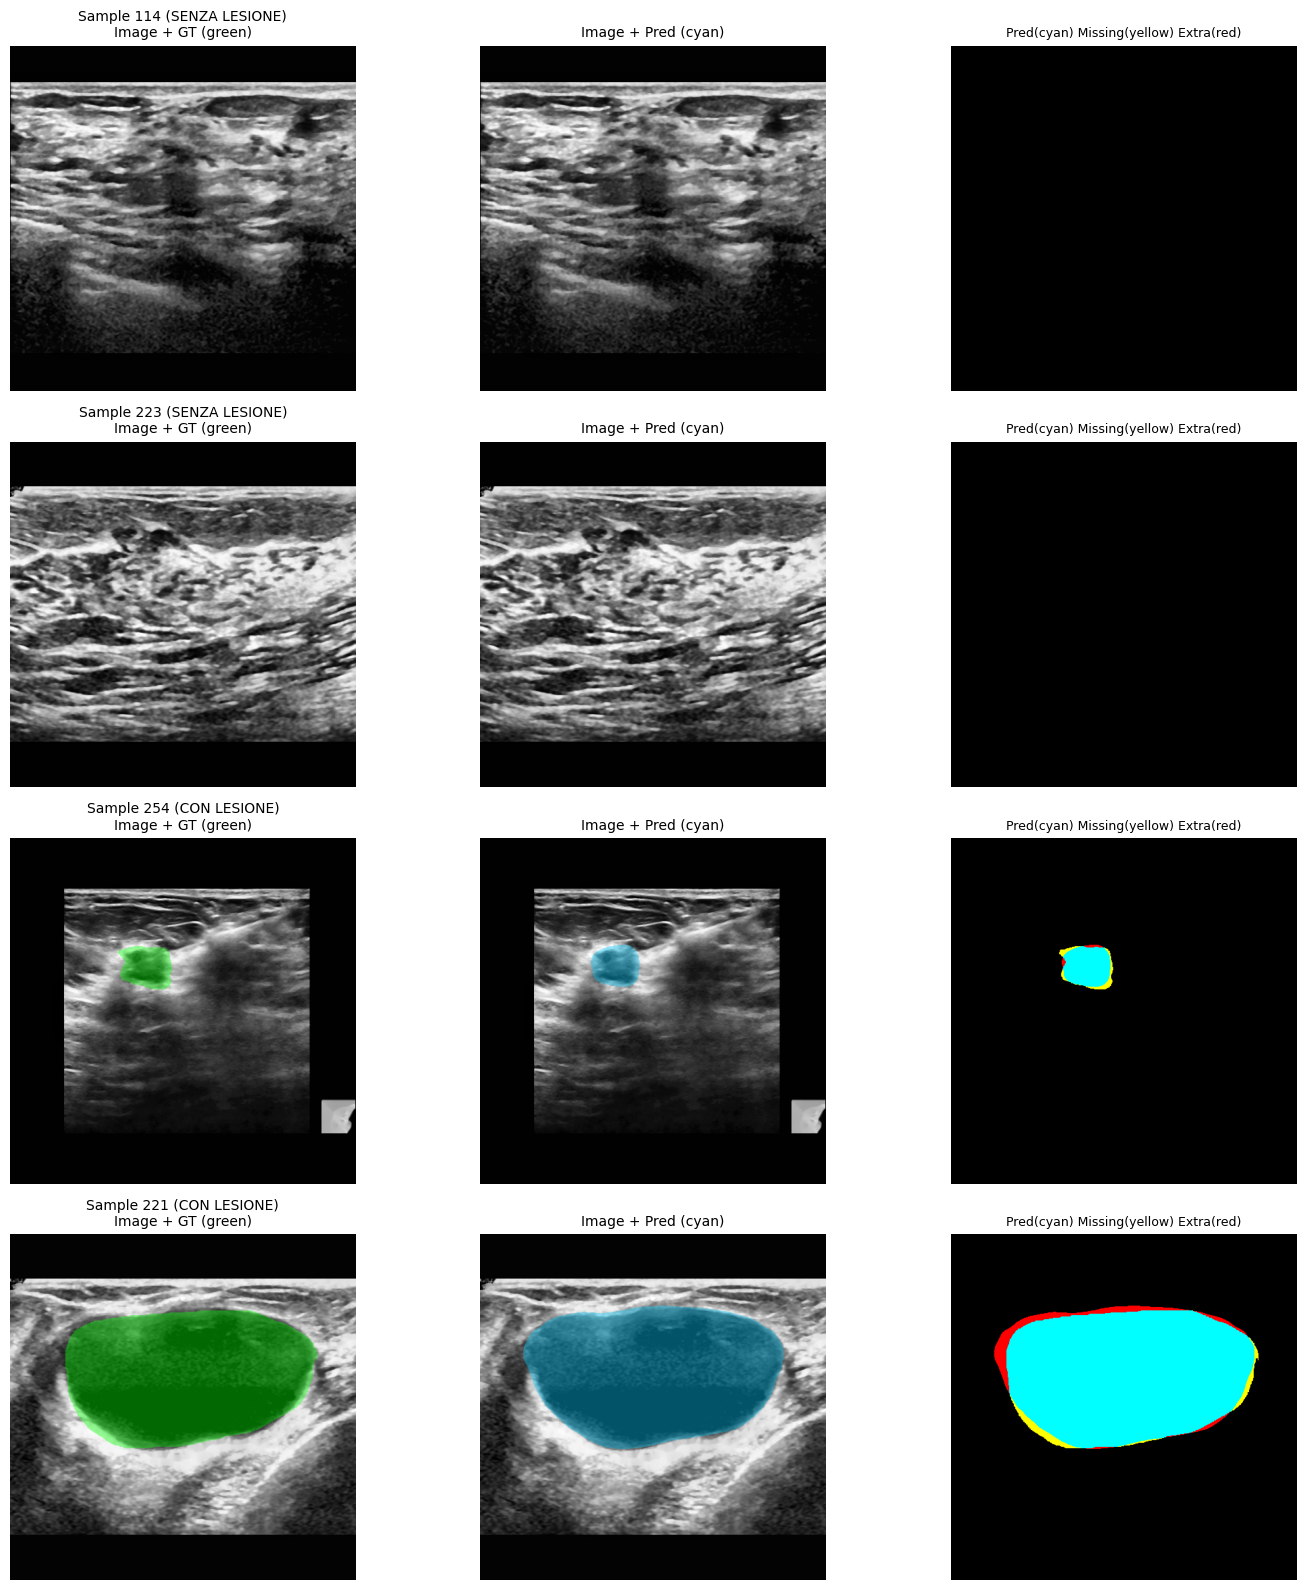

Train 56:   0%|          | 0/293 [00:00<?, ?it/s]

KeyboardInterrupt: 

In [17]:
model = DualHeadSegFormerDeepSup(num_classes=Config.NUM_CLASSES).to(Config.DEVICE)
optimizer = Ranger21(
    model.parameters(), lr=Config.LEARNING_RATE, weight_decay=Config.WEIGHT_DECAY,
    num_epochs=Config.NUM_EPOCHS, num_batches_per_epoch=len(train_loader)
)

from torch.optim.lr_scheduler import CosineAnnealingWarmRestarts
scheduler = CosineAnnealingWarmRestarts(optimizer, T_0=10, T_mult=2, eta_min=1e-6)

criterion = CombinedSegmentationLoss(Config)

history = {
    'train_loss': [], 'val_loss': [],
    'val_mean_dice': [], 'val_mean_recall': [], 'val_mean_precision': []
}

best_mean_dice = 0.0
patience_counter = 0

val_gt_all = np.array([np.asarray(val_dataset[i]['mask']) for i in range(len(val_dataset))])
lesion_idx_all = np.where((val_gt_all != 0).sum(axis=(1, 2)) > 0)[0]
no_lesion_idx_all = np.where((val_gt_all != 0).sum(axis=(1, 2)) == 0)[0]

np.random.seed(42)
fixed_vis_indices = []
if len(no_lesion_idx_all) >= 2:
    fixed_vis_indices.extend(np.random.choice(no_lesion_idx_all, 2, replace=False).tolist())
elif len(no_lesion_idx_all) == 1:
    fixed_vis_indices.append(no_lesion_idx_all[0])
if len(lesion_idx_all) >= 2:
    fixed_vis_indices.extend(np.random.choice(lesion_idx_all, 2, replace=False).tolist())
elif len(lesion_idx_all) == 1:
    fixed_vis_indices.append(lesion_idx_all[0])
np.random.seed(None)

print(f"\n{'='*80}")
print("🚀 TRAINING V2: Lovász + Cosine Annealing + Advanced Augmentation")
print(f"{'='*80}")
print(f"📌 Campioni fissi per visualizzazione: {fixed_vis_indices}\n")

for epoch in range(Config.NUM_EPOCHS):

    train_losses, train_det_acc = train_one_epoch(
        model, train_loader, optimizer, criterion, Config.DEVICE, epoch, train_dataset
    )
    

    val_losses, val_metrics, val_pred_masks, val_gt_masks = validate(
        model, val_loader, criterion, Config.DEVICE, epoch
    )
    

    gating_status = "🔒 GATING ATTIVO" if epoch >= Config.GATING_WARMUP_EPOCHS else "⏳ Warm-up (no gating)"
    

    history['train_loss'].append(train_losses['total'])
    history['val_loss'].append(val_losses['total'])
    history['val_mean_dice'].append(val_metrics['mean_lesion_dice'])
    history['val_mean_recall'].append(val_metrics['mean_lesion_recall'])
    history['val_mean_precision'].append(val_metrics['mean_lesion_precision'])
    

    scheduler.step()
    current_lr = scheduler.get_last_lr()[0]
    

    print(f"\n📊 Epoch {epoch+1}/{Config.NUM_EPOCHS} {gating_status} | LR: {current_lr:.2e}")
    print(f"Train Loss: {train_losses['total']:.4f} | Det Acc: {train_det_acc:.4f}")
    print(f"Val Loss: {val_losses['total']:.4f} | Det Acc: {val_metrics['detection_acc']:.4f}")
    print(f"Val Dice: {val_metrics['mean_lesion_dice']:.4f} | Recall: {val_metrics['mean_lesion_recall']:.4f} | Precision: {val_metrics['mean_lesion_precision']:.4f}")
    

    if (epoch + 1) % 5 == 0 and len(fixed_vis_indices) > 0:
        print(f"\n🎨 Visualization epoch {epoch+1} (campioni fissi)...")
        

        vis_imgs = np.array([np.asarray(val_dataset[i]['image']).squeeze(0) for i in fixed_vis_indices])
        vis_imgs = np.expand_dims(vis_imgs, axis=1)
        vis_gts = np.array([np.asarray(val_dataset[i]['mask']) for i in fixed_vis_indices])
        
        with torch.no_grad():
            vis_tensor = torch.from_numpy(vis_imgs).float().to(Config.DEVICE)
            det_logits, seg_logits = model(vis_tensor, return_aux=False)
            
            det_probs = F.softmax(det_logits, dim=1)
            det_confidence = det_probs[:, 1]
            vis_preds = torch.argmax(seg_logits, dim=1)
            
            if epoch >= Config.GATING_WARMUP_EPOCHS:
                for b in range(vis_preds.shape[0]):
                    if det_confidence[b] < Config.DETECTION_THRESHOLD:
                        vis_preds[b] = 0
            
            vis_preds = vis_preds.cpu().numpy()
        
        n_samples = len(fixed_vis_indices)
        fig, axes = plt.subplots(n_samples, 3, figsize=(15, 4*n_samples))
        if n_samples == 1:
            axes = axes.reshape(1, -1)
        
        for i, sample_idx in enumerate(fixed_vis_indices):
            img = vis_imgs[i, 0]
            gt = vis_gts[i]
            pred = vis_preds[i]
            
            img_display = ((img - img.min()) / (img.max() - img.min() + 1e-8) * 255).astype(np.uint8)
            img_rgb = cv2.cvtColor(img_display, cv2.COLOR_GRAY2RGB)
            
            gt_overlay = img_rgb.copy()
            gt_overlay[gt == 1] = [0, 255, 0]
            gt_overlay = cv2.addWeighted(img_rgb, 0.6, gt_overlay, 0.4, 0)
            axes[i, 0].imshow(gt_overlay)
            has_les = "CON LESIONE" if gt.sum() > 0 else "SENZA LESIONE"
            axes[i, 0].set_title(f"Sample {sample_idx} ({has_les})\nImage + GT (green)", fontsize=10)
            axes[i, 0].axis('off')
            
            pred_overlay = img_rgb.copy()
            pred_overlay[pred == 1] = [0, 200, 255]
            pred_overlay = cv2.addWeighted(img_rgb, 0.6, pred_overlay, 0.4, 0)
            axes[i, 1].imshow(pred_overlay)
            axes[i, 1].set_title(f"Image + Pred (cyan)", fontsize=10)
            axes[i, 1].axis('off')
            
            diff_display = np.zeros((*gt.shape, 3), dtype=np.uint8)
            tp = (gt == 1) & (pred == 1)
            fp = (gt == 0) & (pred == 1)
            fn = (gt == 1) & (pred == 0)
            diff_display[tp] = [0, 255, 255]
            diff_display[fn] = [255, 255, 0]
            diff_display[fp] = [255, 0, 0]
            axes[i, 2].imshow(diff_display)
            axes[i, 2].set_title(f"Pred(cyan) Missing(yellow) Extra(red)", fontsize=9)
            axes[i, 2].axis('off')
        
        plt.tight_layout()
        plt.show()
        plt.close(fig)
    
    if torch.cuda.is_available():
        torch.cuda.empty_cache()
    
    if val_metrics['mean_lesion_dice'] > best_mean_dice:
        best_mean_dice = val_metrics['mean_lesion_dice']
        torch.save({
            'model_state_dict': model.state_dict(),
            'optimizer_state_dict': optimizer.state_dict(),
            'epoch': epoch,
            'mean_dice': best_mean_dice
        }, 'best_segmentation.pt')
        print(f"✅ Best model saved! Dice: {best_mean_dice:.4f}")
        patience_counter = 0
    else:
        patience_counter += 1
    
    if patience_counter >= Config.PATIENCE:
        print(f"\n⏹️ Early stopping at epoch {epoch+1}")
        break

print(f"\n\n{'='*80}")
print("✅ TRAINING COMPLETE")
print(f"{'='*80}")
print(f"Best Mean Dice: {best_mean_dice:.4f}")

model.eval()


## Results


📈 Training curves:


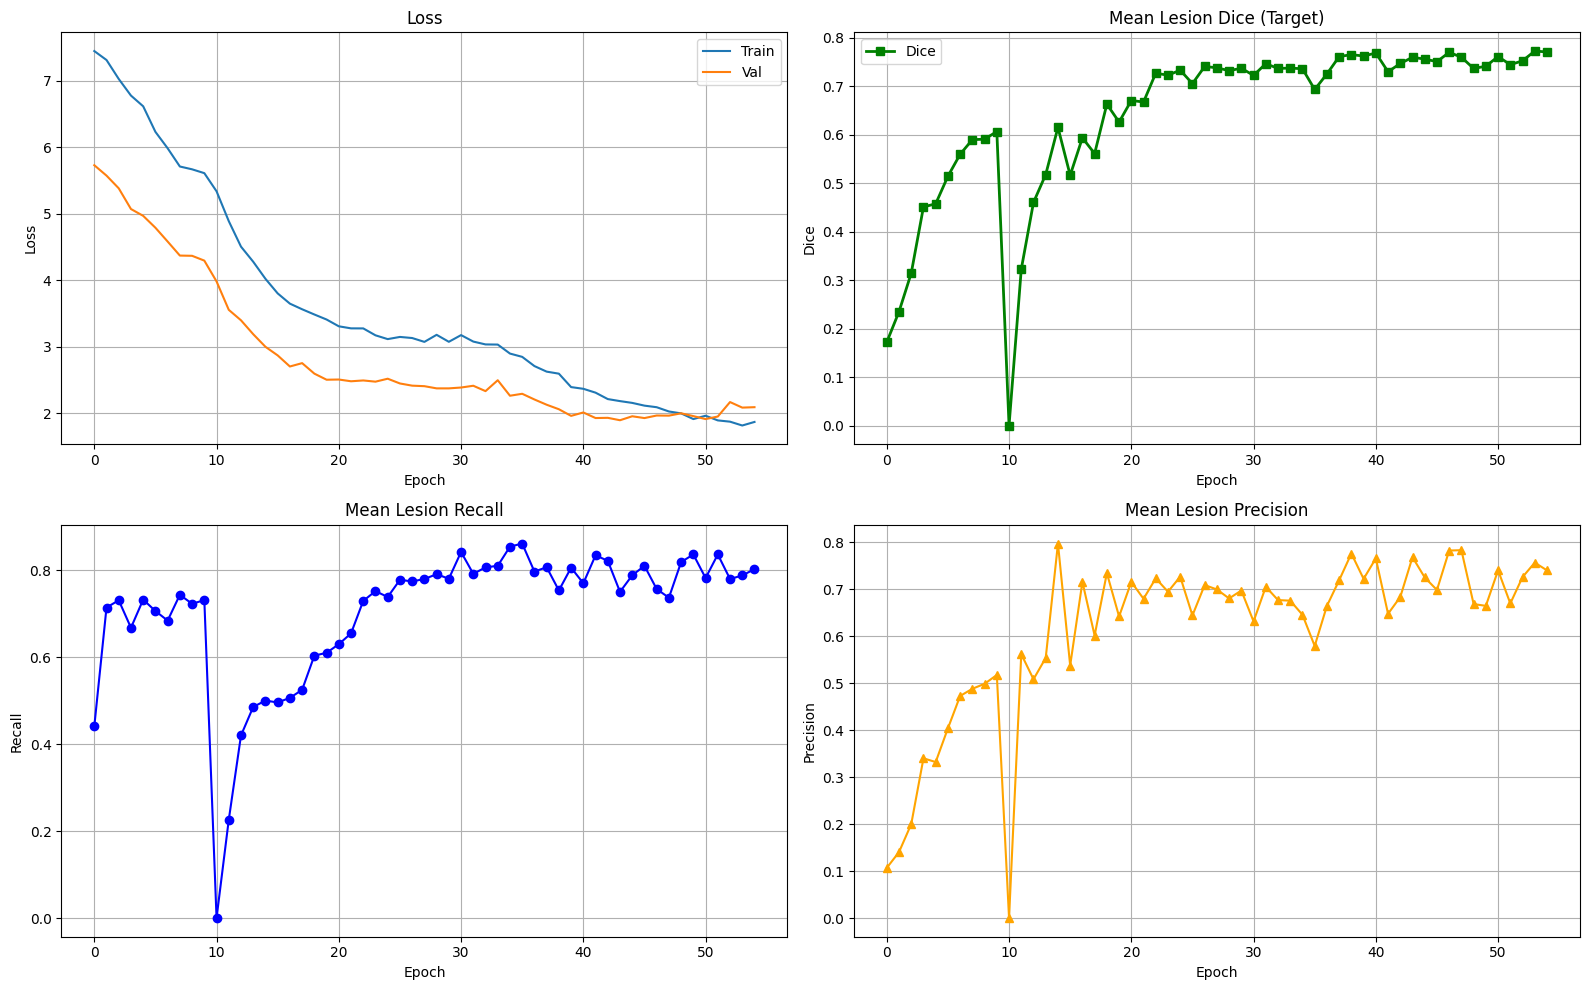

In [18]:
# Training curves
print("\n📈 Training curves:")
plot_training_curves(history)

## Confronto Finale per Classe

Some weights of SegformerForSemanticSegmentation were not initialized from the model checkpoint at nvidia/segformer-b2-finetuned-ade-512-512 and are newly initialized because the shapes did not match:
- decode_head.classifier.weight: found shape torch.Size([150, 768, 1, 1]) in the checkpoint and torch.Size([2, 768, 1, 1]) in the model instantiated
- decode_head.classifier.bias: found shape torch.Size([150]) in the checkpoint and torch.Size([2]) in the model instantiated
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


✅ Best model loaded from epoch 53 (Dice: 0.7721)

📊 Confronto finale: 2 con lesione + 2 senza (random)

Selected random samples: [143, 293, 271, 266]


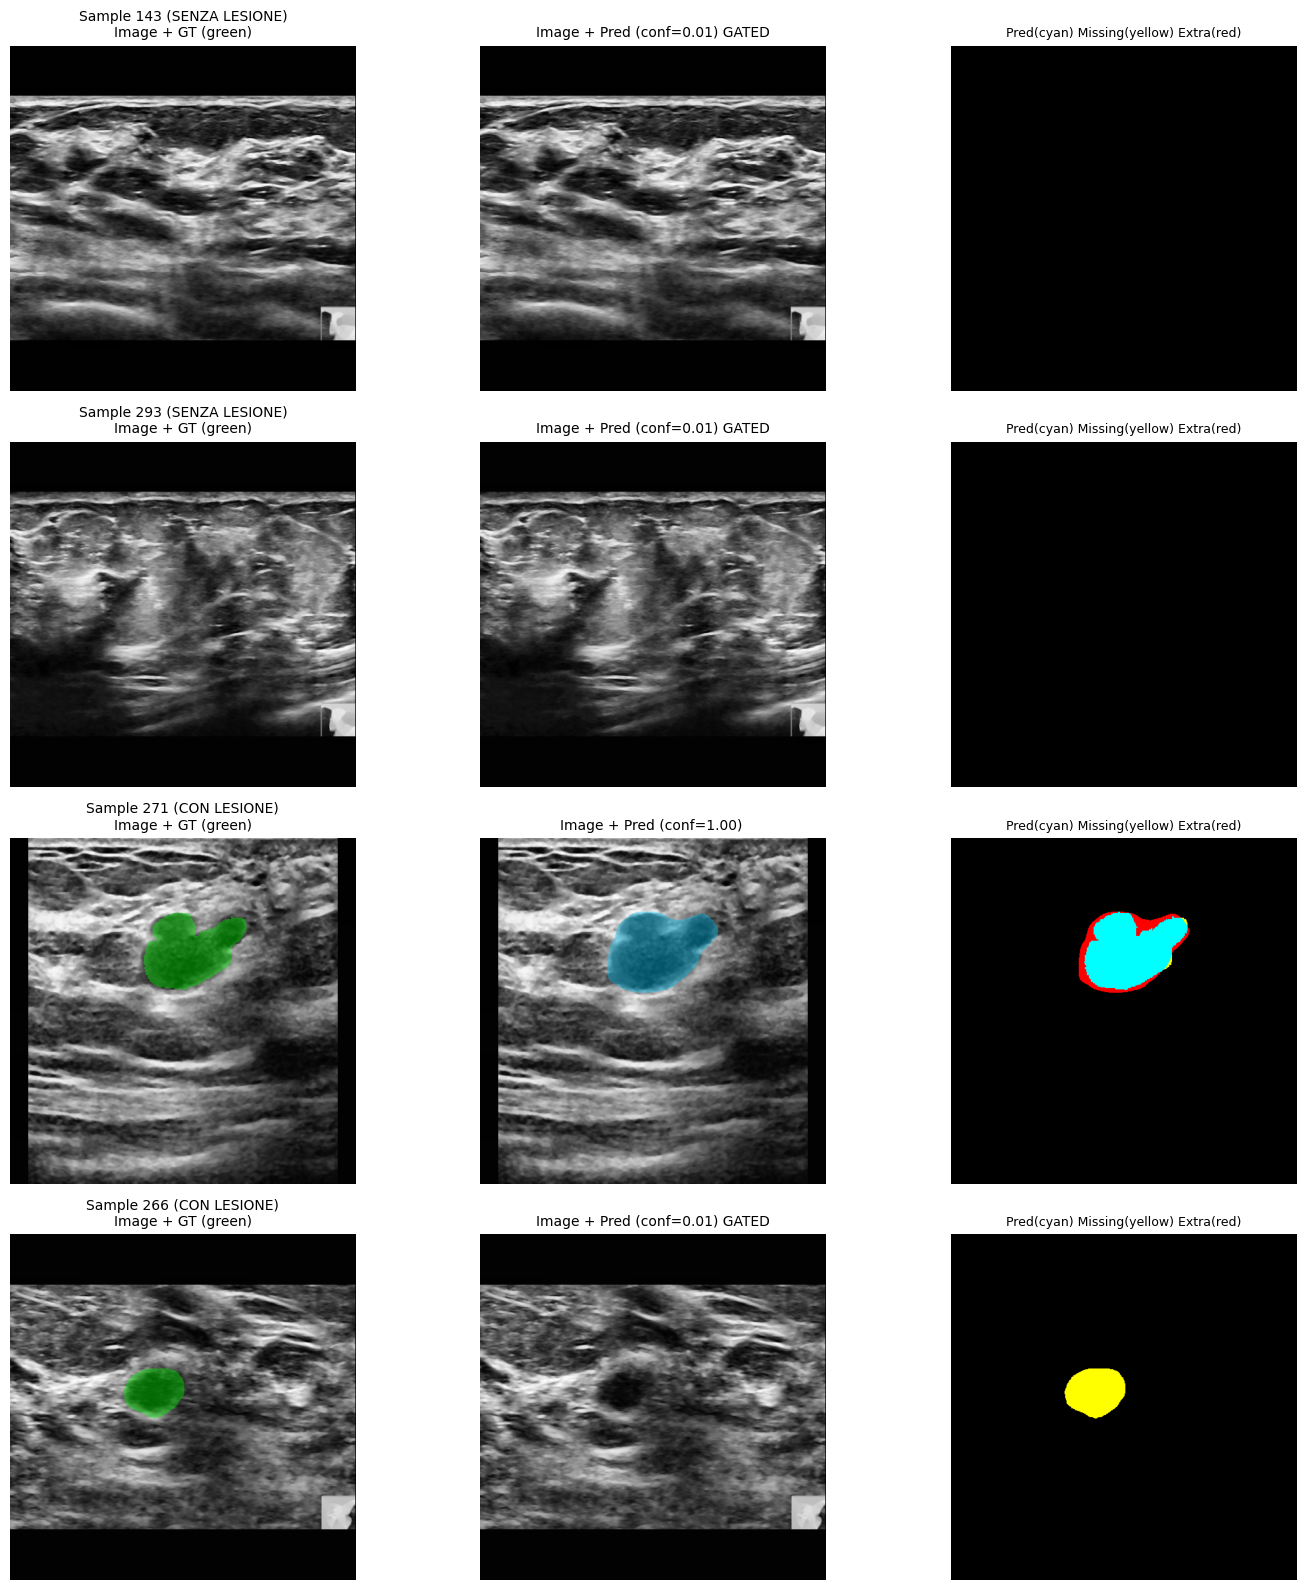


📈 METRICHE PER CAMPIONE

🔬 Sample 143 (SENZA LESIONE) [GATED]:
   Detection confidence: 0.0063
   FP pixels = 0 ✅ ZERO FP!

🔬 Sample 293 (SENZA LESIONE) [GATED]:
   Detection confidence: 0.0076
   FP pixels = 0 ✅ ZERO FP!

🔬 Sample 271 (CON LESIONE):
   Detection confidence: 0.9999
   Dice=0.8906  Recall=0.9918  Precision=0.8082

🔬 Sample 266 (CON LESIONE) [GATED]:
   Detection confidence: 0.0110
   Dice=0.0000  Recall=0.0000  Precision=0.0000



In [29]:
model = DualHeadSegFormerDeepSup(num_classes=Config.NUM_CLASSES).to(Config.DEVICE)

checkpoint = torch.load('best_segmentation.pt', weights_only=False)
model.load_state_dict(checkpoint['model_state_dict'])
model.eval()

print(f"✅ Best model loaded from epoch {checkpoint['epoch']} (Dice: {checkpoint['mean_dice']:.4f})")
print("\n📊 Confronto finale: 2 con lesione + 2 senza (random)\n")

val_gt_all = np.array([np.asarray(val_dataset[i]['mask']) for i in range(len(val_dataset))])

no_lesion_idx = np.where((val_gt_all != 0).sum(axis=(1, 2)) == 0)[0]
with_lesion_idx = np.where((val_gt_all != 0).sum(axis=(1, 2)) > 0)[0]

np.random.seed(None)
selected_indices = []

if len(no_lesion_idx) >= 2:
    selected_indices.extend(np.random.choice(no_lesion_idx, 2, replace=False).tolist())
elif len(no_lesion_idx) == 1:
    selected_indices.append(no_lesion_idx[0])
if len(with_lesion_idx) >= 2:
    selected_indices.extend(np.random.choice(with_lesion_idx, 2, replace=False).tolist())
elif len(with_lesion_idx) == 1:
    selected_indices.append(with_lesion_idx[0])

print(f"Selected random samples: {selected_indices}")

val_imgs = np.array([np.asarray(val_dataset[i]['image']).squeeze(0) for i in selected_indices])
val_imgs = np.expand_dims(val_imgs, axis=1)
val_gts = np.array([np.asarray(val_dataset[i]['mask']) for i in selected_indices])

with torch.no_grad():
    val_imgs_tensor = torch.from_numpy(val_imgs).float().to(Config.DEVICE)
    det_logits, seg_logits = model(val_imgs_tensor, return_aux=False)
    
    det_probs = F.softmax(det_logits, dim=1)
    det_confidence = det_probs[:, 1]
    val_preds = torch.argmax(seg_logits, dim=1)
    
    for b in range(val_preds.shape[0]):
        if det_confidence[b] < Config.DETECTION_THRESHOLD:
            val_preds[b] = 0
    
    val_preds = val_preds.cpu().numpy()
    det_confidence_np = det_confidence.cpu().numpy()

n_samples = len(selected_indices)
fig, axes = plt.subplots(n_samples, 3, figsize=(15, 4*n_samples))
if n_samples == 1:
    axes = axes.reshape(1, -1)

for i, sample_idx in enumerate(selected_indices):
    img = val_imgs[i, 0]
    gt = val_gts[i]
    pred = val_preds[i]
    
    img_display = ((img - img.min()) / (img.max() - img.min() + 1e-8) * 255).astype(np.uint8)
    img_rgb = cv2.cvtColor(img_display, cv2.COLOR_GRAY2RGB)
    
    gt_overlay = img_rgb.copy()
    gt_overlay[gt == 1] = [0, 255, 0]
    gt_overlay = cv2.addWeighted(img_rgb, 0.6, gt_overlay, 0.4, 0)
    axes[i, 0].imshow(gt_overlay)
    has_les = "CON LESIONE" if gt.sum() > 0 else "SENZA LESIONE"
    axes[i, 0].set_title(f"Sample {sample_idx} ({has_les})\nImage + GT (green)", fontsize=10)
    axes[i, 0].axis('off')
    
    pred_overlay = img_rgb.copy()
    pred_overlay[pred == 1] = [0, 200, 255]
    pred_overlay = cv2.addWeighted(img_rgb, 0.6, pred_overlay, 0.4, 0)
    axes[i, 1].imshow(pred_overlay)
    det_conf = det_confidence_np[i]
    gated = "GATED" if det_conf < Config.DETECTION_THRESHOLD else ""
    axes[i, 1].set_title(f"Image + Pred (conf={det_conf:.2f}) {gated}", fontsize=10)
    axes[i, 1].axis('off')
    
    diff_display = np.zeros((*gt.shape, 3), dtype=np.uint8)
    tp = (gt == 1) & (pred == 1)
    fp = (gt == 0) & (pred == 1)
    fn = (gt == 1) & (pred == 0)
    diff_display[tp] = [0, 255, 255]
    diff_display[fn] = [255, 255, 0]
    diff_display[fp] = [255, 0, 0]
    axes[i, 2].imshow(diff_display)
    axes[i, 2].set_title(f"Pred(cyan) Missing(yellow) Extra(red)", fontsize=9)
    axes[i, 2].axis('off')

plt.tight_layout()
plt.show()

print("\n" + "="*70)
print("📈 METRICHE PER CAMPIONE")
print("="*70)

for i, sample_idx in enumerate(selected_indices):
    gt = val_gts[i]
    pred = val_preds[i]
    det_conf = det_confidence_np[i]
    
    has_lesion = gt.sum() > 0
    sample_type = "CON LESIONE" if has_lesion else "SENZA LESIONE"
    gated = " [GATED]" if det_conf < Config.DETECTION_THRESHOLD else ""
    
    print(f"\n🔬 Sample {sample_idx} ({sample_type}){gated}:")
    print(f"   Detection confidence: {det_conf:.4f}")
    
    if has_lesion:
        dice = f1_score(gt.flatten(), pred.flatten(), pos_label=1, zero_division=0)
        recall = recall_score(gt.flatten(), pred.flatten(), pos_label=1, zero_division=0)
        precision = precision_score(gt.flatten(), pred.flatten(), pos_label=1, zero_division=0)
        
        print(f"   Dice={dice:.4f}  Recall={recall:.4f}  Precision={precision:.4f}")
    else:
        fp_pixels = (pred == 1).sum()
        print(f"   FP pixels = {fp_pixels} {'✅ ZERO FP!' if fp_pixels == 0 else '⚠️'}")

print("\n" + "="*70)
